In [1]:
import numpy as np
import pandas as pd
import pickle
import jax.numpy as jnp
import jax.random as jr
from itertools import product

import midplane_model as mm          # model_z0, model_h_eff, run_grid_fit, fit_flare_bin, etc.
from src.coords import build_segment_setup, between_ccw

# --- Load the two sim extracts ---
sims = {
    "merger": pd.read_csv("sim_disc_merger.csv"),
    "host":   pd.read_csv("sim_disc_host.csv"),
}
for name, df in sims.items():
    print(name, len(df), "stars")

# --- Shared binning + fitting settings (matched to your real APOGEE pipeline) ---
z_edges          = np.linspace(-3.0, 3.0, 181)
R_edges          = np.arange(0.5, 15.5 + 0.5, 0.5)
minN_seg_total   = 15
min_bin_count    = 5
min_bins_for_fit = 8
z_fit_min, z_fit_max = -1.5, 1.5
zlim             = 0.6
R_centers        = 0.5 * (R_edges[:-1] + R_edges[1:])

mm.Z_BINS_FIT = z_edges  # module defaults to np.arange(-5,5,0.1); override to match your real z_edges

# --- Tracer error: sim has no per-star measurement uncertainty like APOGEE spectra do,
# so use a small, effectively-negligible constant and let bin_one's intrinsic-scatter
# term (population spread / sqrt(N)) drive the actual per-bin uncertainty.
OFE_ERR_PLACEHOLDER = 1e-4

# --- Virtual "Sun" azimuth for the wedge, since the sim has no real Sun ---
phi0 = np.pi

merger 42137146 stars
host 52647375 stars


In [2]:
print(pd.read_csv("sim_disc_merger.csv", nrows=0).columns.tolist())

['R', 'phi', 'z', 'age', 'feh', 'ofe']


In [3]:
prepared = {}

for name, df in sims.items():
    R = df["R"].to_numpy()
    z = df["z"].to_numpy()
    phi = df["phi"].to_numpy()
    tracer = df["ofe"].to_numpy()

    # match build_star_pack's rmax_keep=16 cut
    finite = np.isfinite(R) & np.isfinite(z) & np.isfinite(phi) & np.isfinite(tracer)
    keep = finite & (R < 16.0)

    R = R[keep]
    z = z[keep]
    phi = phi[keep]
    tracer = tracer[keep]
    tracer_err = np.full_like(tracer, OFE_ERR_PLACEHOLDER, dtype=float)

    segm, crowd_bounds, window_edges, seg_diag = build_segment_setup(
        phi, phi0=phi0, crowd_halfwidth_deg=45, n_crowd=11
    )
    SEG_PLOT_heat = list(range(1, seg_diag["n_crowd"] + 1))

    prepared[name] = dict(
        R=R, z=z, phi=phi, tracer=tracer, tracer_err=tracer_err,
        segm=segm, crowd_bounds=crowd_bounds, window_edges=window_edges,
        SEG_PLOT_heat=SEG_PLOT_heat,
    )

    print(f"{name}: {len(R)} stars after R<16 cut, "
          f"{sum(segm[i].sum() for i in SEG_PLOT_heat)} in the fit wedge "
          f"(vs {segm[seg_diag['seg_rest_id']].sum()} outside it)")

merger: 39919183 stars after R<16 cut, 10011350 in the fit wedge (vs 29907833 outside it)
host: 49289381 stars after R<16 cut, 12666588 in the fit wedge (vs 36622793 outside it)


In [4]:
import os
import pickle

per_cell_z0 = {}
z0_summary = {}

FORCE_RERUN = False   # set True to ignore any cached .pkl and refit everything

for name, d in prepared.items():
    seg_masks_fit = {i: d["segm"][i] for i in d["SEG_PLOT_heat"]}
    results_path = f"sim_grid_fit_z0_{name}.pkl"

    if os.path.exists(results_path) and not FORCE_RERUN:
        print(f"[{name}_z0] loading cached fit from {results_path}")
        with open(results_path, "rb") as f:
            cached = pickle.load(f)
        per_cell_z0[name] = cached["per_cell"]
    else:
        per_cell_z0[name] = mm.run_grid_fit(
            d["R"], d["z"], d["tracer"], d["tracer_err"],
            seg_masks_fit, R_edges,
            model_fn=mm.model_z0,
            label=f"{name}_z0",
            results_path=results_path,
            minN_total=minN_seg_total,
            min_bin_count=min_bin_count,
            min_bins_for_fit=min_bins_for_fit,
            z_fit_min=z_fit_min, z_fit_max=z_fit_max,
        )

    z0_med, z0_std, _, _ = mm.summarize_grid_fit(
        per_cell_z0[name], n_R=len(R_edges) - 1, n_seg=len(seg_masks_fit)
    )
    z0_summary[name] = dict(z0_med=z0_med, z0_std=z0_std)

[merger_z0] loading cached fit from sim_grid_fit_z0_merger.pkl


summarizing grid fit: 100%|███████████████████| 330/330 [06:56<00:00,  1.26s/it]


[host_z0] loading cached fit from sim_grid_fit_z0_host.pkl


summarizing grid fit: 100%|███████████████████| 330/330 [07:03<00:00,  1.28s/it]


In [5]:
import os
import pickle

per_cell_heff = {}
heff_summary = {}

FORCE_RERUN = False   # set True to ignore any cached .pkl and refit everything

for name, d in prepared.items():
    seg_masks_fit = {i: d["segm"][i] for i in d["SEG_PLOT_heat"]}
    results_path = f"sim_grid_fit_h_eff_{name}.pkl"

    if os.path.exists(results_path) and not FORCE_RERUN:
        print(f"[{name}_h_eff] loading cached fit from {results_path}")
        with open(results_path, "rb") as f:
            cached = pickle.load(f)
        per_cell_heff[name] = cached["per_cell"]
    else:
        per_cell_heff[name] = mm.run_grid_fit(
            d["R"], d["z"], d["tracer"], d["tracer_err"],
            seg_masks_fit, R_edges,
            model_fn=mm.model_h_eff,
            label=f"{name}_h_eff",
            results_path=results_path,
            minN_total=minN_seg_total,
            min_bin_count=min_bin_count,
            min_bins_for_fit=min_bins_for_fit,
            z_fit_min=z_fit_min, z_fit_max=z_fit_max,
        )

    _, _, h_eff_med, h_eff_std = mm.summarize_grid_fit(
        per_cell_heff[name], n_R=len(R_edges) - 1, n_seg=len(seg_masks_fit)
    )
    heff_summary[name] = dict(h_eff_med=h_eff_med, h_eff_std=h_eff_std)

[merger_h_eff] loading cached fit from sim_grid_fit_h_eff_merger.pkl


summarizing grid fit: 100%|███████████████████| 330/330 [06:58<00:00,  1.27s/it]


[host_h_eff] loading cached fit from sim_grid_fit_h_eff_host.pkl


summarizing grid fit: 100%|███████████████████| 330/330 [04:15<00:00,  1.29it/s]


In [6]:
import os
import pickle

per_R_flare = {}
flare_summary = {}

FORCE_RERUN = False   # set True to ignore any cached .pkl and refit everything

for name, d in prepared.items():
    # restrict to the wedge (matches the real data's inherent footprint) before collapsing
    in_wedge = np.zeros_like(d["R"], dtype=bool)
    for i in d["SEG_PLOT_heat"]:
        in_wedge |= d["segm"][i]

    R_w = d["R"][in_wedge]
    z_w = d["z"][in_wedge]
    tracer_w = d["tracer"][in_wedge]
    tracer_err_w = d["tracer_err"][in_wedge]

    results_path = f"sim_flare_fit_{name}.pkl"

    if os.path.exists(results_path) and not FORCE_RERUN:
        print(f"[{name}_flare] loading cached fit from {results_path}")
        with open(results_path, "rb") as f:
            per_R_flare[name] = pickle.load(f)
    else:
        per_R_flare[name] = mm.fit_flare_bin(
            R_w, z_w, tracer_w, tracer_err_w, R_centers,
            model_fn=mm.model_h_eff,
            R_width=1.0,
            label=f"{name}_flare",
            results_path=results_path,
            minN_total=minN_seg_total,
            min_bin_count=min_bin_count,
            min_bins_for_fit=min_bins_for_fit,
            z_fit_min=z_fit_min, z_fit_max=z_fit_max,
        )

    h_eff_med_flare, h_eff_std_flare = mm.compute_h_eff_flare(per_R_flare[name])
    flare_summary[name] = dict(h_eff_med=h_eff_med_flare, h_eff_std=h_eff_std_flare)

[merger_flare] loading cached fit from sim_flare_fit_merger.pkl


computing flare h_eff: 100%|████████████████████| 30/30 [00:09<00:00,  3.07it/s]


[host_flare] loading cached fit from sim_flare_fit_host.pkl


computing flare h_eff: 100%|████████████████████| 30/30 [00:09<00:00,  3.16it/s]


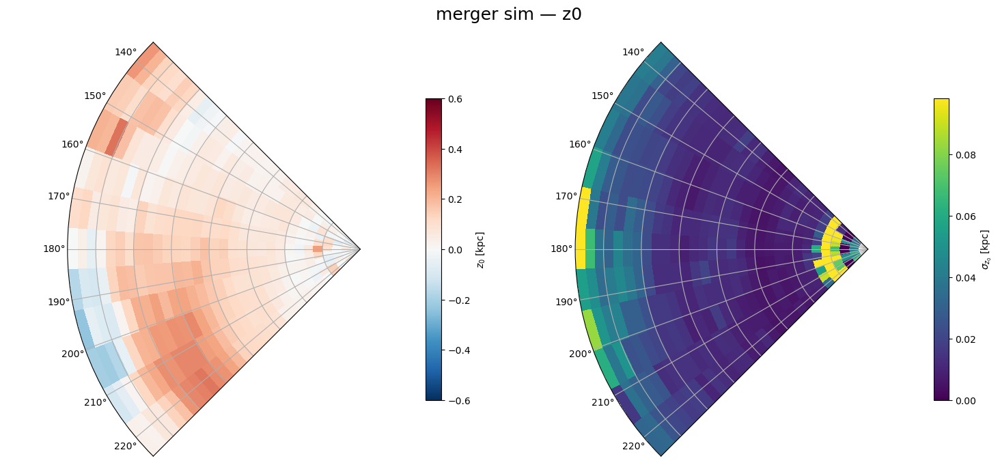

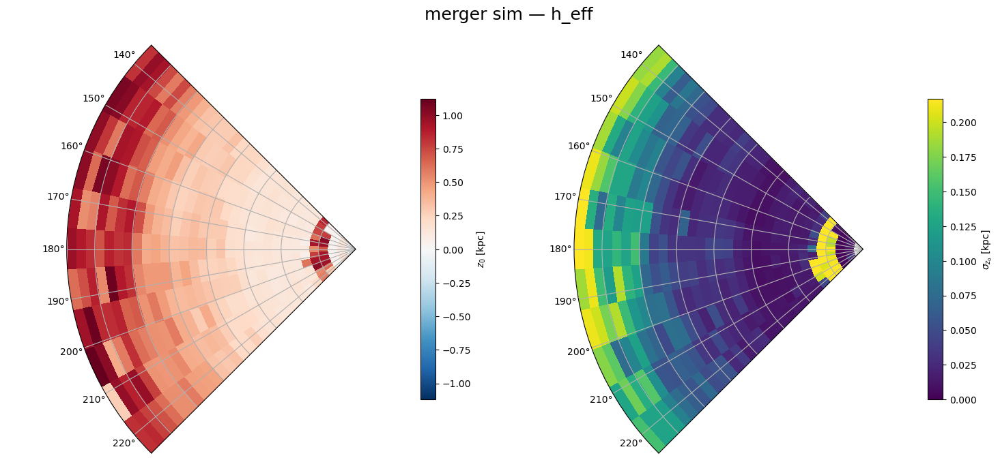

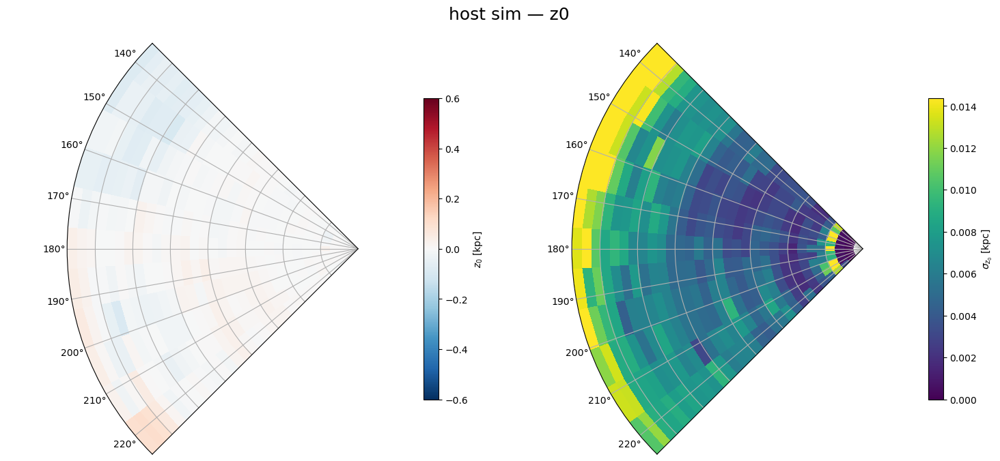

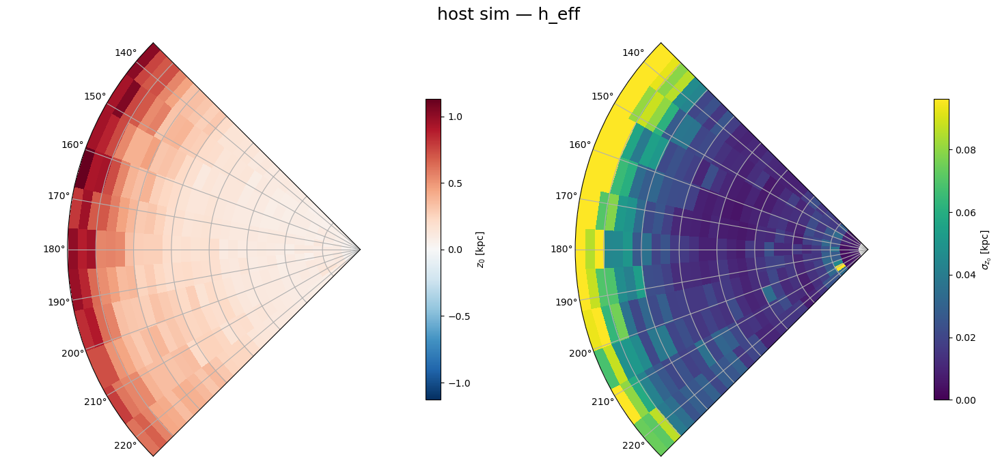

In [7]:
import matplotlib.pyplot as plt

def plot_z0_heatmap_sim(z0_med_bin, z0_std_bin, label, crowd_bounds, n_seg):
    theta_edges = np.unwrap(np.array(crowd_bounds, float))
    for i in range(1, len(theta_edges)):
        while theta_edges[i] <= theta_edges[i - 1]:
            theta_edges[i] += 2 * np.pi
    assert len(theta_edges) - 1 == n_seg

    T_mesh, R_mesh = np.meshgrid(theta_edges, R_edges)
    Zmap_med = np.ma.masked_invalid(z0_med_bin)
    Zmap_std = np.ma.masked_invalid(z0_std_bin)
    std_max = (float(np.nanpercentile(z0_std_bin[np.isfinite(z0_std_bin)], 95))
               if np.isfinite(z0_std_bin).any() else 1.0)
    theta_min, theta_max = theta_edges[0], theta_edges[-1]

    fig = plt.figure(figsize=(15, 7))
    fig.suptitle(label, fontsize=18)

    ax1 = plt.subplot(1, 2, 1, projection="polar")
    pcm1 = ax1.pcolormesh(T_mesh, R_mesh, Zmap_med, cmap="RdBu_r", vmin=-zlim, vmax=zlim, shading="flat")
    fig.colorbar(pcm1, ax=ax1, pad=0.01, shrink=0.7, label=r"$z_0$ [kpc]")
    ax1.set_theta_zero_location("E"); ax1.set_theta_direction(1)
    ax1.set_rmax(R_edges[-1])
    ax1.set_thetamin(np.degrees(theta_min)); ax1.set_thetamax(np.degrees(theta_max))
    ax1.set_yticklabels([])

    ax2 = plt.subplot(1, 2, 2, projection="polar")
    pcm2 = ax2.pcolormesh(T_mesh, R_mesh, Zmap_std, cmap="viridis", vmin=0.0, vmax=std_max, shading="flat")
    fig.colorbar(pcm2, ax=ax2, pad=0.01, shrink=0.7, label=r"$\sigma_{z_0}$ [kpc]")
    ax2.set_theta_zero_location("E"); ax2.set_theta_direction(1)
    ax2.set_rmax(R_edges[-1])
    ax2.set_thetamin(np.degrees(theta_min)); ax2.set_thetamax(np.degrees(theta_max))
    ax2.set_yticklabels([])

    plt.tight_layout()
    plt.show()


for name, d in prepared.items():
    zlim = 0.6  # fixed for z0
    plot_z0_heatmap_sim(
        z0_summary[name]["z0_med"], z0_summary[name]["z0_std"],
        f"{name} sim — z0", d["crowd_bounds"], len(d["SEG_PLOT_heat"])
    )
    zlim = float(np.nanmax(heff_summary[name]["h_eff_med"]))  # auto-scale for h_eff
    plot_z0_heatmap_sim(
        heff_summary[name]["h_eff_med"], heff_summary[name]["h_eff_std"],
        f"{name} sim — h_eff", d["crowd_bounds"], len(d["SEG_PLOT_heat"])
    )

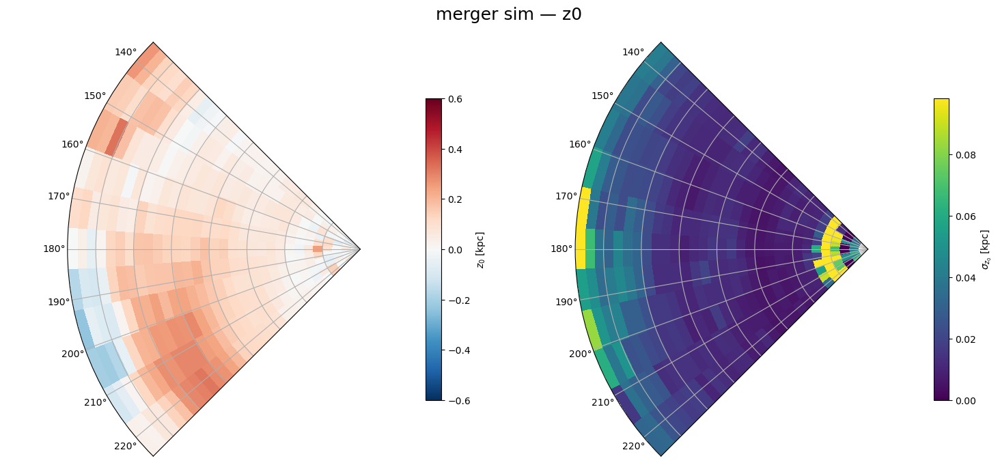

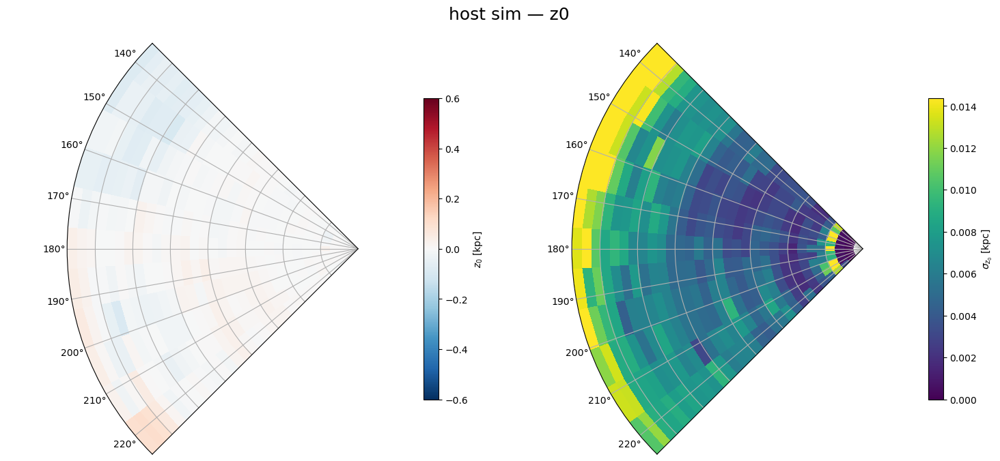

In [46]:
for name, d in prepared.items():
    plot_z0_heatmap_sim(
        z0_summary[name]["z0_med"], z0_summary[name]["z0_std"],
        f"{name} sim — z0", d["crowd_bounds"], len(d["SEG_PLOT_heat"])
    )

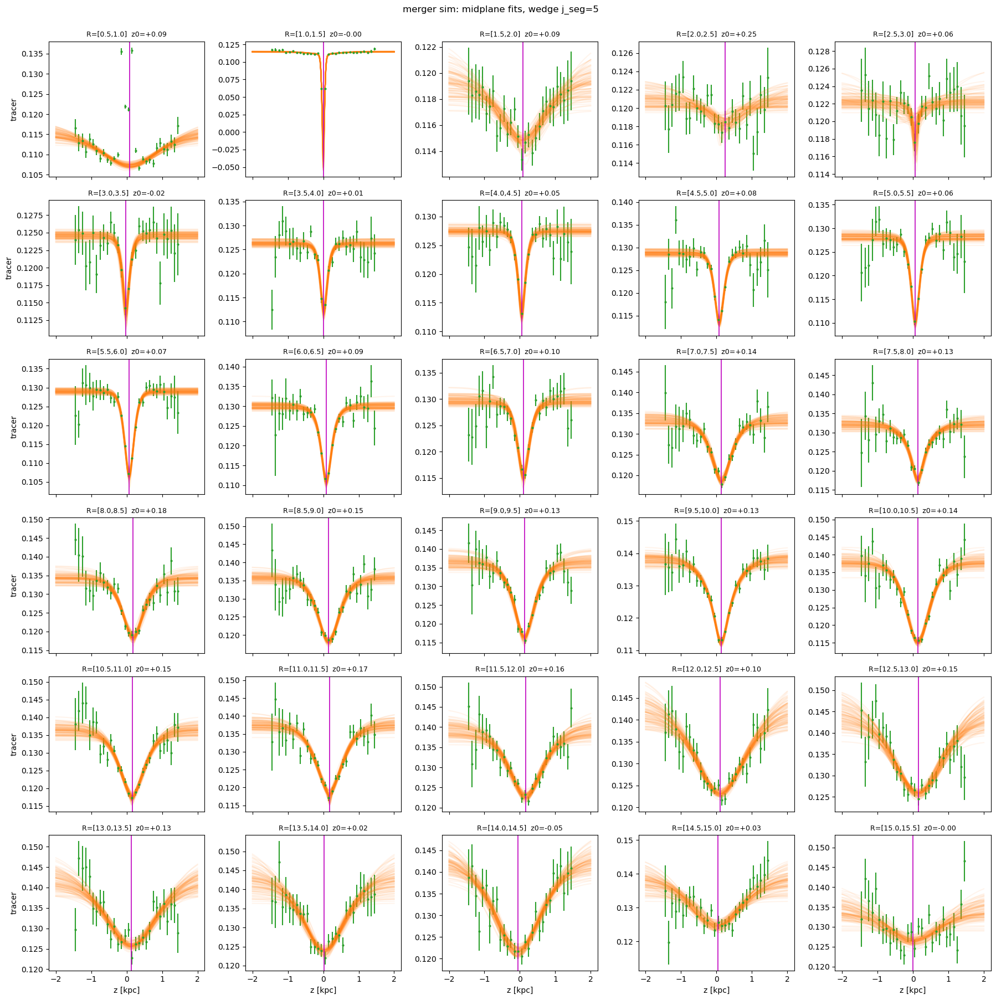

In [60]:
def plot_wedge_fits(per_cell, j_seg, R_edges, ncols=5, n_draws=100, name="merger"):
    i_Rs = sorted(i for (i, j) in per_cell if j == j_seg)
    if not i_Rs:
        print(f"no fitted cells for j_seg={j_seg}")
        return
    n = len(i_Rs)
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(3.6 * ncols, 3.0 * nrows),
                             sharex=True, squeeze=False)
    z_grid = np.linspace(-2, 2, 300)

    for k, ax in enumerate(axes.flat):
        if k >= n:
            ax.axis("off")
            continue
        i_R = i_Rs[k]
        cell = per_cell[(i_R, j_seg)]
        s = cell["samples"]

        ax.errorbar(cell["z_binc"], cell["mean"], yerr=cell["err"],
                    color="C2", linestyle="", marker=".", ms=4)
        for i in range(min(n_draws, len(s["A1"]))):
            h2 = s["h1"][i] + s["d_h2"][i]
            y = mm.mixture_of_sech2(z_grid, s["A1"][i], s["A2"][i], s["h1"][i], h2, s["z0"][i]) + s["offset"][i]
            ax.plot(z_grid, y, color="C1", alpha=0.08)
        z0m = np.median(s["z0"])
        ax.axvline(z0m, color="m", lw=1.2)
        ax.set_title(f"R=[{R_edges[i_R]:.1f},{R_edges[i_R+1]:.1f}]  z0={z0m:+.2f}", fontsize=9)

    for ax in axes[-1]:
        ax.set_xlabel("z [kpc]")
    for ax in axes[:, 0]:
        ax.set_ylabel("tracer")
    fig.suptitle(f"{name} sim: midplane fits, wedge j_seg={j_seg}", y=1.0)
    plt.tight_layout()
    plt.show()

# pick a wedge (0-based index into the 11 segments; 5 is the middle one, centered on the Sun direction)
plot_wedge_fits(per_cell_z0["merger"], j_seg=5, R_edges=R_edges)

In [63]:
def stars_in_heatmap(name):
    d = prepared[name]
    z0_med = z0_summary[name]["z0_med"]           # same grid the heatmap plots
    used = np.zeros(len(d["R"]), dtype=bool)
    for i_R in range(z0_med.shape[0]):
        for j_seg in range(z0_med.shape[1]):
            if not np.isfinite(z0_med[i_R, j_seg]):
                continue
            seg_id = d["SEG_PLOT_heat"][j_seg]
            used |= (d["segm"][seg_id]
                     & (d["R"] >= R_edges[i_R]) & (d["R"] < R_edges[i_R + 1]))
    # stars only enter the fit inside the z fitting window
    used &= (d["z"] >= z_fit_min) & (d["z"] <= z_fit_max)
    return used

def heatmap_age_range(name, host_fix_csv=None):
    df = sims[name]
    age_full = sim_age(name, df, host_fix_csv)      # sim_age from my previous cell (tform -> age for merger)
    if age_full is None:
        return
    R = df["R"].to_numpy(); z = df["z"].to_numpy()
    phi = df["phi"].to_numpy(); tr = df["ofe"].to_numpy()
    keep = np.isfinite(R) & np.isfinite(z) & np.isfinite(phi) & np.isfinite(tr) & (R < 16.0)
    age = age_full[keep]                              # aligned with prepared[name]
    assert len(age) == len(prepared[name]["R"])

    used = stars_in_heatmap(name)
    a = age[used & np.isfinite(age)]
    p = np.percentile(a, [1, 16, 50, 84, 99])
    print(f"{name}: {len(a):,} stars in heatmap cells")
    print(f"  age min/max     : {a.min():.2f} / {a.max():.2f} Gyr")
    print(f"  median          : {p[2]:.2f} Gyr")
    print(f"  16-84 percentile: {p[1]:.2f} - {p[3]:.2f} Gyr")
    print(f"  1-99 percentile : {p[0]:.2f} - {p[4]:.2f} Gyr")

heatmap_age_range("merger")

merger: converting tform -> age (T_SNAP - tform)
merger: 8,295,242 stars in heatmap cells
  age min/max     : -0.52 / 10.32 Gyr
  median          : 8.07 Gyr
  16-84 percentile: 4.84 - 9.58 Gyr
  1-99 percentile : -0.09 - 10.27 Gyr


In [64]:
age = df["age"].to_numpy().astype(float)
print("age range:", np.nanmin(age), "-", np.nanmax(age))   # ~ -0.5..10 => age, ~12.7..23.5 => tform
# age = 23.0068 - age     # uncomment only if the range above looks like formation time

# stars in the cells that made the heatmap (finite z0), within the z fitting window
used = np.zeros(len(R), dtype=bool)
for i_R in range(z0_med.shape[0]):
    for j_seg in range(z0_med.shape[1]):
        if np.isfinite(z0_med[i_R, j_seg]):
            used |= segm[SEG_PLOT_heat[j_seg]] & (R >= R_edges[i_R]) & (R < R_edges[i_R + 1])
used &= (z >= -1.5) & (z <= 1.5) & np.isfinite(age)

a = age[used]
p = np.percentile(a, [1, 16, 50, 84, 99])
print(f"{used.sum():,} stars in heatmap cells")
print(f"min/max: {a.min():.2f} / {a.max():.2f} Gyr   median: {p[2]:.2f}")
print(f"16-84%: {p[1]:.2f} - {p[3]:.2f}   1-99%: {p[0]:.2f} - {p[4]:.2f}")

age range: 2.881236929472632 - 7.441591043637734


ValueError: operands could not be broadcast together with shapes (19046056,) (52647375,) 

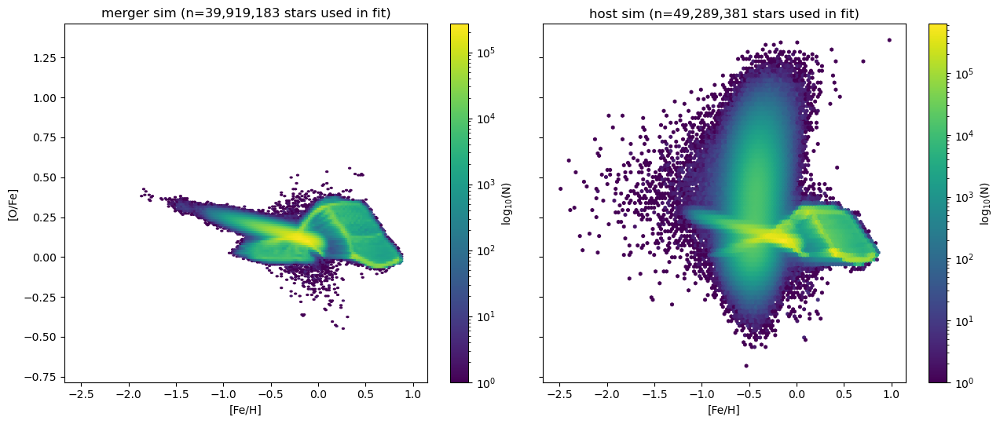

In [31]:
import numpy as np
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), sharex=True, sharey=True)

for ax, (name, df) in zip(axes, sims.items()):
    R = df["R"].to_numpy()
    z = df["z"].to_numpy()
    phi = df["phi"].to_numpy()
    tracer = df["ofe"].to_numpy()
    feh = df["feh"].to_numpy()

    # same mask as cell 2 (finite R/z/phi/tracer, R < 16)
    finite = np.isfinite(R) & np.isfinite(z) & np.isfinite(phi) & np.isfinite(tracer)
    keep = finite & (R < 16.0)

    feh_fit = feh[keep]
    ofe_fit = tracer[keep]
    good = np.isfinite(feh_fit) & np.isfinite(ofe_fit)

    h = ax.hexbin(feh_fit[good], ofe_fit[good], gridsize=120, cmap="viridis",
                  bins="log", mincnt=1)
    ax.set_xlabel("[Fe/H]")
    ax.set_title(f"{name} sim (n={good.sum():,} stars used in fit)")
    fig.colorbar(h, ax=ax, label="log$_{10}$(N)")

axes[0].set_ylabel("[O/Fe]")
plt.tight_layout()
plt.show()

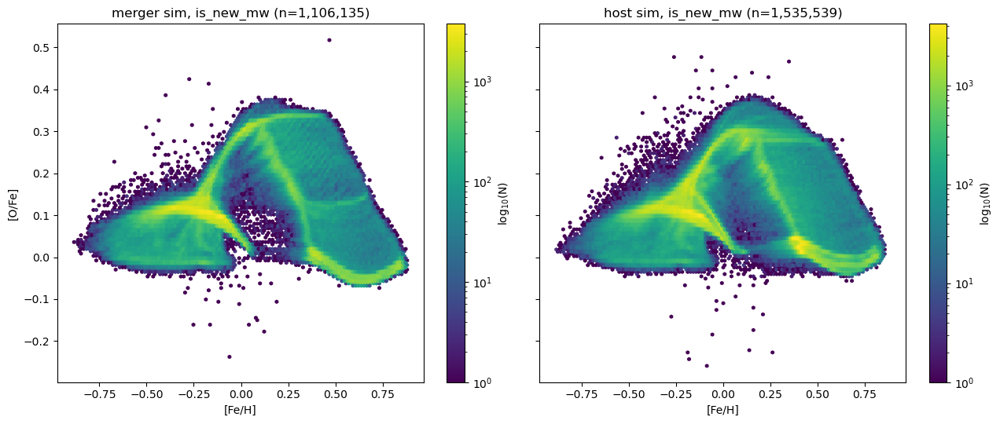

In [33]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sims_tagged = {
    "merger": pd.read_parquet("merger_sim_disc_all.parquet"),
    "host":   pd.read_parquet("host_sim_disc_all.parquet"),
}

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), sharex=True, sharey=True)

for ax, (name, df) in zip(axes, sims_tagged.items()):
    R = df["R"].to_numpy()
    feh = df["feh"].to_numpy()
    ofe = df["ofe"].to_numpy()
    is_new_mw = df["is_new_mw"].to_numpy()

    finite = np.isfinite(R) & np.isfinite(feh) & np.isfinite(ofe)
    keep = finite & is_new_mw & (R < 16.0)

    feh_new = feh[keep]
    ofe_new = ofe[keep]

    h = ax.hexbin(feh_new, ofe_new, gridsize=120, cmap="viridis", bins="log", mincnt=1)
    ax.set_xlabel("[Fe/H]")
    ax.set_title(f"{name} sim, is_new_mw (n={keep.sum():,})")
    fig.colorbar(h, ax=ax, label="log$_{10}$(N)")

axes[0].set_ylabel("[O/Fe]")
plt.tight_layout()
plt.show()

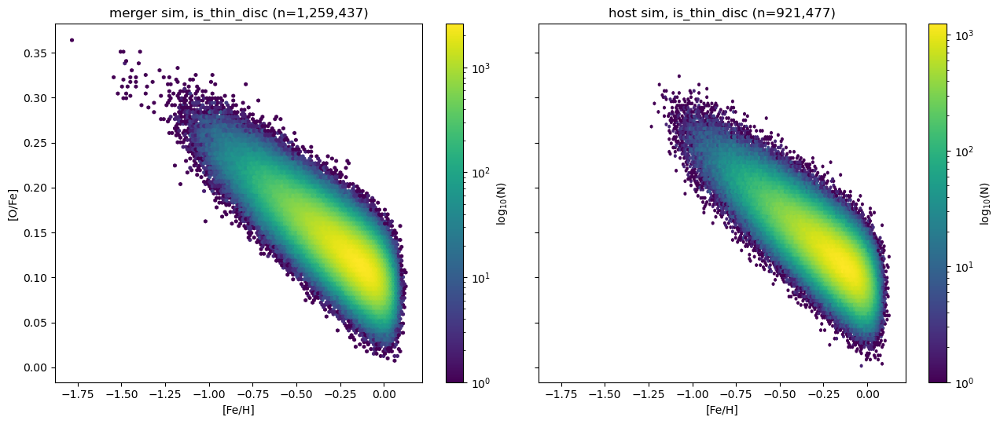

In [34]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sims_tagged = {
    "merger": pd.read_parquet("merger_sim_disc_all.parquet"),
    "host":   pd.read_parquet("host_sim_disc_all.parquet"),
}

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), sharex=True, sharey=True)

for ax, (name, df) in zip(axes, sims_tagged.items()):
    R = df["R"].to_numpy()
    feh = df["feh"].to_numpy()
    ofe = df["ofe"].to_numpy()
    is_thin_disc = df["is_thin_disc"].to_numpy()

    finite = np.isfinite(R) & np.isfinite(feh) & np.isfinite(ofe)
    keep = finite & is_thin_disc & (R < 16.0)

    feh_thin = feh[keep]
    ofe_thin = ofe[keep]

    h = ax.hexbin(feh_thin, ofe_thin, gridsize=120, cmap="viridis", bins="log", mincnt=1)
    ax.set_xlabel("[Fe/H]")
    ax.set_title(f"{name} sim, is_thin_disc (n={keep.sum():,})")
    fig.colorbar(h, ax=ax, label="log$_{10}$(N)")

axes[0].set_ylabel("[O/Fe]")
plt.tight_layout()
plt.show()

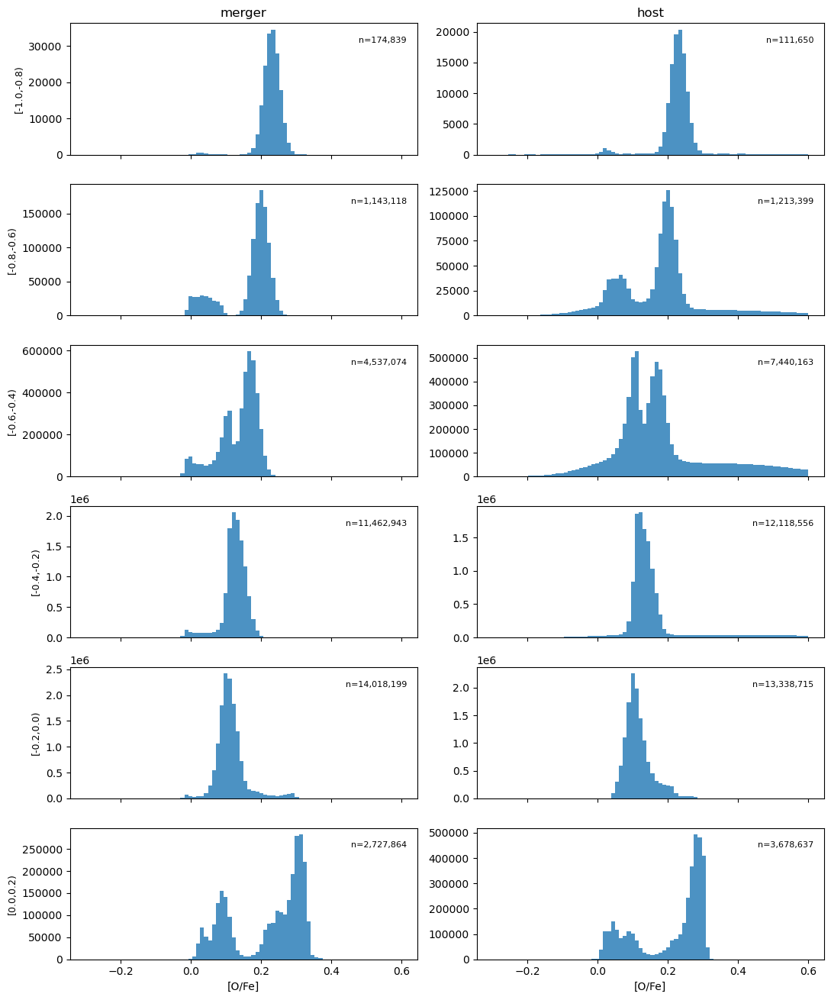

In [32]:
import numpy as np
import matplotlib.pyplot as plt

# narrow [Fe/H] slices to check for bimodality in [O/Fe] at fixed metallicity
feh_slices = [(-1.0, -0.8), (-0.8, -0.6), (-0.6, -0.4), (-0.4, -0.2), (-0.2, 0.0), (0.0, 0.2)]

fig, axes = plt.subplots(len(feh_slices), 2, figsize=(11, 2.2 * len(feh_slices)),
                          sharex=True)

for col, (name, df) in enumerate(sims.items()):
    R = df["R"].to_numpy()
    z = df["z"].to_numpy()
    phi = df["phi"].to_numpy()
    tracer = df["ofe"].to_numpy()
    feh = df["feh"].to_numpy()

    finite = np.isfinite(R) & np.isfinite(z) & np.isfinite(phi) & np.isfinite(tracer) & np.isfinite(feh)
    keep = finite & (R < 16.0)

    feh_fit = feh[keep]
    ofe_fit = tracer[keep]

    for row, (flo, fhi) in enumerate(feh_slices):
        ax = axes[row, col]
        m = (feh_fit >= flo) & (feh_fit < fhi)
        n = int(m.sum())
        if n > 10:
            ax.hist(ofe_fit[m], bins=80, range=(-0.3, 0.6), color="C0", alpha=0.8)
        ax.text(0.97, 0.85, f"n={n:,}", transform=ax.transAxes, ha="right", fontsize=8)
        if col == 0:
            ax.set_ylabel(f"[{flo:.1f},{fhi:.1f})", fontsize=9)
        if row == 0:
            ax.set_title(name)
        if row == len(feh_slices) - 1:
            ax.set_xlabel("[O/Fe]")

plt.tight_layout()
plt.show()

Most extreme z0 cells, merger sim:
  (i_R=27, j_seg=2)  R=[14.0,14.5]  z0=+0.326 ± 0.023
  (i_R=20, j_seg=10)  R=[10.5,11.0]  z0=+0.320 ± 0.015
  (i_R=21, j_seg=10)  R=[11.0,11.5]  z0=+0.303 ± 0.010
  (i_R=19, j_seg=9)  R=[10.0,10.5]  z0=+0.294 ± 0.013
  (i_R=20, j_seg=9)  R=[10.5,11.0]  z0=+0.293 ± 0.012
  (i_R=22, j_seg=10)  R=[11.5,12.0]  z0=+0.293 ± 0.017
  (i_R=21, j_seg=9)  R=[11.0,11.5]  z0=+0.291 ± 0.014
  (i_R=18, j_seg=8)  R=[9.5,10.0]  z0=+0.288 ± 0.011
  (i_R=19, j_seg=10)  R=[10.0,10.5]  z0=+0.286 ± 0.013
  (i_R=23, j_seg=9)  R=[12.0,12.5]  z0=+0.280 ± 0.014
  (i_R=20, j_seg=8)  R=[10.5,11.0]  z0=+0.273 ± 0.014
  (i_R=23, j_seg=10)  R=[12.0,12.5]  z0=+0.272 ± 0.018
  (i_R=19, j_seg=8)  R=[10.0,10.5]  z0=+0.270 ± 0.009
  (i_R=22, j_seg=9)  R=[11.5,12.0]  z0=+0.270 ± 0.014
  (i_R=18, j_seg=10)  R=[9.5,10.0]  z0=+0.269 ± 0.010


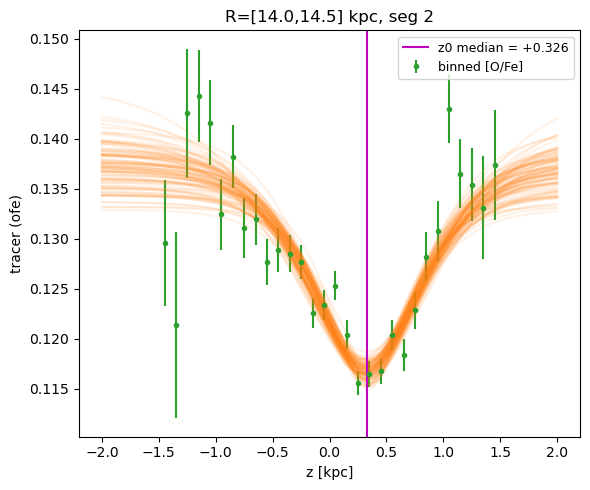

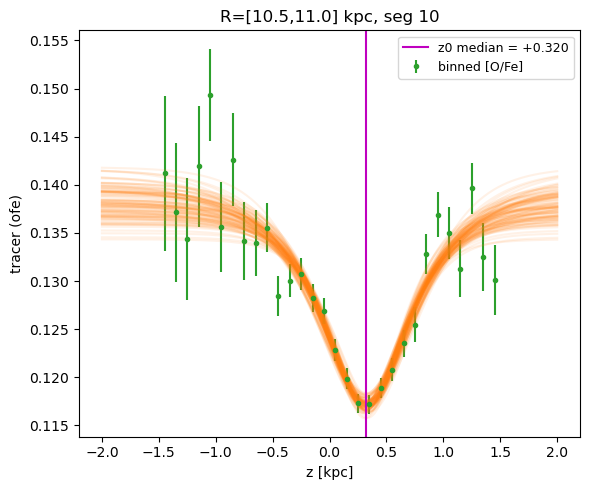

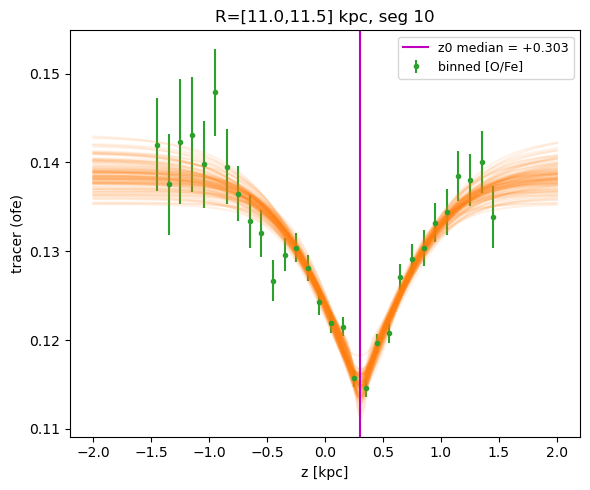

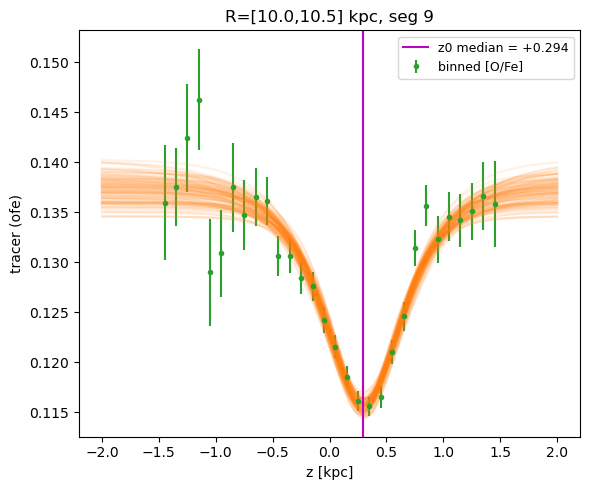

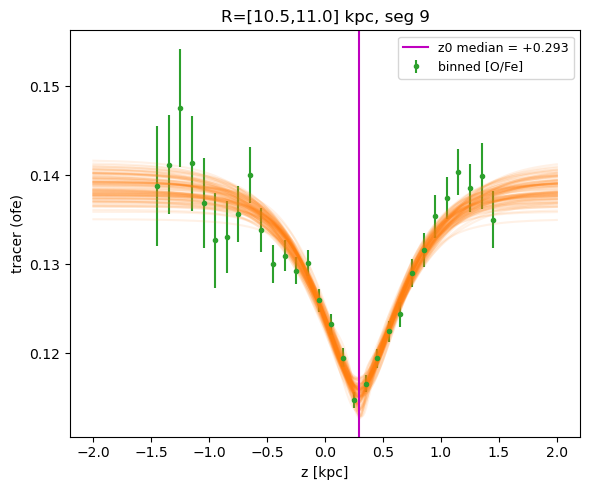

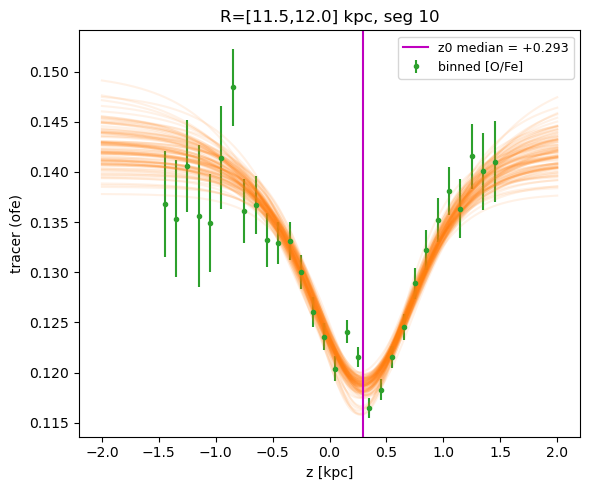

In [29]:
import numpy as np
import matplotlib.pyplot as plt

z0_grid = z0_summary["merger"]["z0_med"]
z0_err_grid = z0_summary["merger"]["z0_std"]

# sort cells by |z0| to surface the most extreme (bluest/reddest) ones first
flat_idx = np.argsort(-np.abs(np.nan_to_num(z0_grid, nan=-np.inf)).ravel())
n_R, n_seg = z0_grid.shape

print("Most extreme z0 cells, merger sim:")
for idx in flat_idx[:15]:
    i_R, j_seg = np.unravel_index(idx, z0_grid.shape)
    val = z0_grid[i_R, j_seg]
    if np.isfinite(val):
        print(f"  (i_R={i_R}, j_seg={j_seg})  R=[{R_edges[i_R]:.1f},{R_edges[i_R+1]:.1f}]  "
              f"z0={val:+.3f} ± {z0_err_grid[i_R,j_seg]:.3f}")

def plot_cell_fit(per_cell, i_R, j_seg, R_edges, title_extra=""):
    cell = per_cell.get((i_R, j_seg))
    if cell is None:
        print(f"no cell data for (i_R={i_R}, j_seg={j_seg})")
        return

    s = cell["samples"]
    z_grid = np.linspace(-2, 2, 300)

    fig, ax = plt.subplots(figsize=(6, 5))
    ax.errorbar(cell["z_binc"], cell["mean"], yerr=cell["err"],
                color="C2", linestyle="", marker=".", label="binned [O/Fe]")

    for i in range(min(100, len(s["A1"]))):
        cs = {k: v[i] for k, v in s.items()}
        cs["h2"] = cs["h1"] + cs["d_h2"]
        y_pred = mm.mixture_of_sech2(z_grid, cs["A1"], cs["A2"], cs["h1"], cs["h2"], cs["z0"]) + cs["offset"]
        ax.plot(z_grid, y_pred, color="C1", alpha=0.1)

    ax.axvline(np.median(s["z0"]), color="m", ls="-", lw=1.5, label=f"z0 median = {np.median(s['z0']):+.3f}")
    ax.set_xlabel("z [kpc]")
    ax.set_ylabel("tracer (ofe)")
    ax.set_title(f"R=[{R_edges[i_R]:.1f},{R_edges[i_R+1]:.1f}] kpc, seg {j_seg}{title_extra}")
    ax.legend(fontsize=9)
    plt.tight_layout()
    plt.show()

# plot the top few most extreme cells
for idx in flat_idx[:6]:
    i_R, j_seg = np.unravel_index(idx, z0_grid.shape)
    if np.isfinite(z0_grid[i_R, j_seg]):
        plot_cell_fit(per_cell_z0["merger"], i_R, j_seg, R_edges)

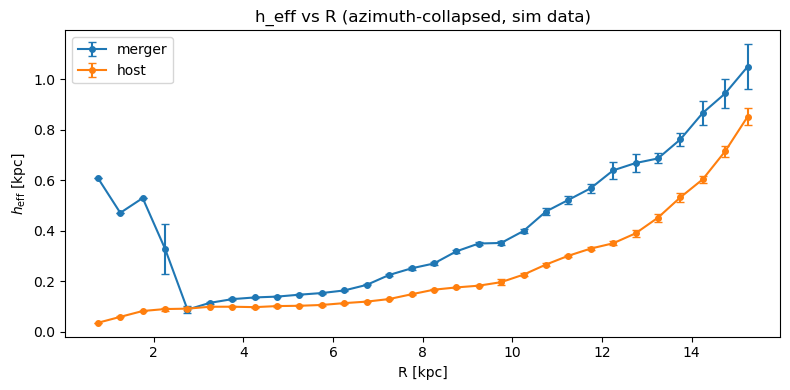

In [8]:
fig, ax = plt.subplots(figsize=(8, 4))

for name in prepared:
    ax.errorbar(
        R_centers, flare_summary[name]["h_eff_med"], yerr=flare_summary[name]["h_eff_std"],
        fmt="o-", ms=4, capsize=3, label=name,
    )

ax.legend()
ax.set_xlabel("R [kpc]")
ax.set_ylabel(r"$h_\mathrm{eff}$ [kpc]")
ax.set_title("h_eff vs R (azimuth-collapsed, sim data)")
plt.tight_layout()
plt.show()

[merger_flare] loading cached fit from sim_flare_fit_merger.pkl


computing flare h_eff: 100%|████████████████████| 30/30 [00:09<00:00,  3.05it/s]


[host_flare] loading cached fit from sim_flare_fit_host.pkl


computing flare h_eff: 100%|████████████████████| 30/30 [00:09<00:00,  3.10it/s]


[merger_flare_z0corr] loading cached fit from sim_flare_fit_merger_z0corr.pkl


computing flare h_eff: 100%|████████████████████| 30/30 [00:09<00:00,  3.26it/s]


[host_flare_z0corr] loading cached fit from sim_flare_fit_host_z0corr.pkl


computing flare h_eff: 100%|████████████████████| 30/30 [00:09<00:00,  3.13it/s]


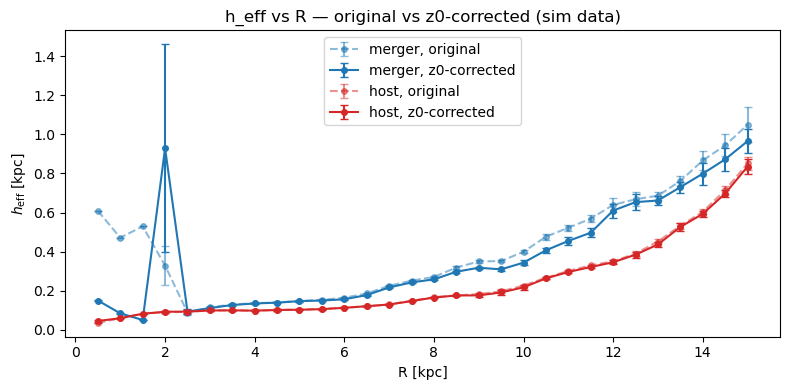

In [10]:
# --- Step 1: build z' = z - z0(cell) for each sim, using its own z0 grid ---
for name, d in prepared.items():
    z0_grid = z0_summary[name]["z0_med"]
    n_R, n_seg = z0_grid.shape

    z_prime = np.full_like(d["z"], np.nan)

    for i_R in range(n_R):
        Rmin, Rmax = float(R_edges[i_R]), float(R_edges[i_R + 1])
        R_mask = (d["R"] >= Rmin) & (d["R"] < Rmax)
        for j_seg in range(n_seg):
            val = z0_grid[i_R, j_seg]
            if not np.isfinite(val):
                continue
            seg_id = d["SEG_PLOT_heat"][j_seg]
            m = R_mask & d["segm"][seg_id]
            z_prime[m] = d["z"][m] - val

    d["z_prime"] = z_prime

# --- Step 2: clean, round-numbered flare-fit bins (separate from the z0 grid's R_edges) ---
R_centers_flare = np.arange(0.5, 15 + 1e-3, 0.5)   # centers 0.5, 1.0, 1.5, ... -> bins [0,1], [0.5,1.5], [1,2], ...
R_width = 1.0

# --- Step 3: original (uncorrected) flare fit, rebinned ---
import os
import pickle

per_R_flare = {}
flare_summary = {}

FORCE_RERUN = False   # set True to ignore any cached .pkl and refit everything

for name, d in prepared.items():
    in_wedge = np.zeros_like(d["R"], dtype=bool)
    for i in d["SEG_PLOT_heat"]:
        in_wedge |= d["segm"][i]

    R_w = d["R"][in_wedge]
    z_w = d["z"][in_wedge]
    tracer_w = d["tracer"][in_wedge]
    tracer_err_w = d["tracer_err"][in_wedge]

    results_path = f"sim_flare_fit_{name}.pkl"

    if os.path.exists(results_path) and not FORCE_RERUN:
        print(f"[{name}_flare] loading cached fit from {results_path}")
        with open(results_path, "rb") as f:
            per_R_flare[name] = pickle.load(f)
    else:
        per_R_flare[name] = mm.fit_flare_bin(
            R_w, z_w, tracer_w, tracer_err_w, R_centers_flare,
            model_fn=mm.model_h_eff,
            R_width=R_width,
            label=f"{name}_flare",
            results_path=results_path,
            minN_total=minN_seg_total,
            min_bin_count=min_bin_count,
            min_bins_for_fit=min_bins_for_fit,
            z_fit_min=z_fit_min, z_fit_max=z_fit_max,
        )

    h_eff_med_flare, h_eff_std_flare = mm.compute_h_eff_flare(per_R_flare[name])
    flare_summary[name] = dict(h_eff_med=h_eff_med_flare, h_eff_std=h_eff_std_flare)
    
# --- Step 4: z0-corrected flare fit, same rebinning ---
per_R_flare_z0corr = {}
flare_summary_z0corr = {}

for name, d in prepared.items():
    in_wedge = np.zeros_like(d["R"], dtype=bool)
    for i in d["SEG_PLOT_heat"]:
        in_wedge |= d["segm"][i]

    finite = np.isfinite(d["z_prime"])
    keep = in_wedge & finite

    R_w = d["R"][keep]
    z_w = d["z_prime"][keep]
    tracer_w = d["tracer"][keep]
    tracer_err_w = d["tracer_err"][keep]

    results_path = f"sim_flare_fit_{name}_z0corr.pkl"

    if os.path.exists(results_path) and not FORCE_RERUN:
        print(f"[{name}_flare_z0corr] loading cached fit from {results_path}")
        with open(results_path, "rb") as f:
            per_R_flare_z0corr[name] = pickle.load(f)
    else:
        per_R_flare_z0corr[name] = mm.fit_flare_bin(
            R_w, z_w, tracer_w, tracer_err_w, R_centers_flare,
            model_fn=mm.model_h_eff,
            R_width=R_width,
            label=f"{name}_flare_z0corr",
            results_path=results_path,
            minN_total=minN_seg_total,
            min_bin_count=min_bin_count,
            min_bins_for_fit=min_bins_for_fit,
            z_fit_min=z_fit_min, z_fit_max=z_fit_max,
        )

    h_eff_med_flare, h_eff_std_flare = mm.compute_h_eff_flare(per_R_flare_z0corr[name])
    flare_summary_z0corr[name] = dict(h_eff_med=h_eff_med_flare, h_eff_std=h_eff_std_flare)
# --- Step 5: plot original vs z0-corrected, per sim ---
fig, ax = plt.subplots(figsize=(8, 4))
sim_colors = {"merger": "C0", "host": "C3"}

for name in prepared:
    ax.errorbar(R_centers_flare, flare_summary[name]["h_eff_med"], yerr=flare_summary[name]["h_eff_std"],
                fmt="o--", ms=4, capsize=3, alpha=0.5, color=sim_colors[name], label=f"{name}, original")
    ax.errorbar(R_centers_flare, flare_summary_z0corr[name]["h_eff_med"], yerr=flare_summary_z0corr[name]["h_eff_std"],
                fmt="o-", ms=4, capsize=3, color=sim_colors[name], label=f"{name}, z0-corrected")

ax.legend()
ax.set_xlabel("R [kpc]")
ax.set_ylabel(r"$h_\mathrm{eff}$ [kpc]")
ax.set_title("h_eff vs R — original vs z0-corrected (sim data)")
plt.tight_layout()
plt.show()

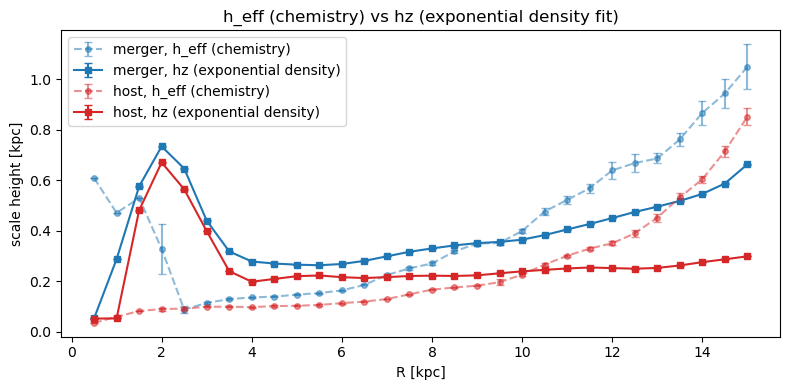

In [13]:
from scipy.optimize import curve_fit

def exp_density_np(z, A, hz, z0):
    return A * np.exp(-np.abs(z - z0) / hz)

def fit_exp_density_curvefit(z_binc, count, count_err):
    A_guess = max(count.max(), 1.0)
    p0 = [A_guess, 0.3, 0.0]
    bounds = ([0, 0.04, -0.5], [A_guess * 5, 3.0, 0.5])
    try:
        popt, pcov = curve_fit(exp_density_np, z_binc, count, p0=p0, sigma=count_err,
                                absolute_sigma=True, bounds=bounds, maxfev=5000)
        hz_val, z0_val = popt[1], popt[2]
        hz_err = np.sqrt(pcov[1, 1]) if np.isfinite(pcov[1, 1]) else np.nan
        z0_err = np.sqrt(pcov[2, 2]) if np.isfinite(pcov[2, 2]) else np.nan
        return hz_val, hz_err, z0_val, z0_err, True
    except Exception:
        return np.nan, np.nan, np.nan, np.nan, False

def select_R_bin_density(R_use, Z_use, Rmin, Rmax, minN_total=15, min_bin_count=5,
                          min_bins_for_fit=8, z_fit_min=-1.5, z_fit_max=1.5):
    m = (R_use >= Rmin) & (R_use < Rmax) & np.isfinite(Z_use)
    n_stars = int(m.sum())
    if n_stars < minN_total:
        return None, None, None, n_stars, False

    z_binc, count, count_err = bin_one_density(Z_use[m])
    good = (count >= min_bin_count) & (z_binc >= z_fit_min) & (z_binc <= z_fit_max)
    if good.sum() < min_bins_for_fit:
        return None, None, None, n_stars, False

    return z_binc[good], count[good], count_err[good], n_stars, True

hz_summary = {}

for name, d in prepared.items():
    in_wedge = np.zeros_like(d["R"], dtype=bool)
    for i in d["SEG_PLOT_heat"]:
        in_wedge |= d["segm"][i]

    R_w = d["R"][in_wedge]
    z_w = d["z"][in_wedge]

    hz_med = np.full(len(R_centers_flare), np.nan)
    hz_err = np.full(len(R_centers_flare), np.nan)

    for i_R, Rc in enumerate(R_centers_flare):
        Rmin, Rmax = Rc - R_width/2, Rc + R_width/2
        z_binc, count, count_err, n_stars, ok = select_R_bin_density(
            R_w, z_w, Rmin, Rmax,
            minN_total=minN_seg_total, min_bin_count=min_bin_count,
            min_bins_for_fit=min_bins_for_fit, z_fit_min=z_fit_min, z_fit_max=z_fit_max,
        )
        if not ok:
            continue
        hz_val, hzerr, z0_val, z0err, fit_ok = fit_exp_density_curvefit(z_binc, count, count_err)
        if fit_ok:
            hz_med[i_R] = hz_val
            hz_err[i_R] = hzerr

    hz_summary[name] = dict(hz_med=hz_med, hz_err=hz_err)

fig, ax = plt.subplots(figsize=(8, 4))
sim_colors = {"merger": "C0", "host": "C3"}

for name in prepared:
    ax.errorbar(R_centers_flare, flare_summary[name]["h_eff_med"], yerr=flare_summary[name]["h_eff_std"],
                fmt="o--", ms=4, capsize=3, alpha=0.5, color=sim_colors[name], label=f"{name}, h_eff (chemistry)")
    ax.errorbar(R_centers_flare, hz_summary[name]["hz_med"], yerr=hz_summary[name]["hz_err"],
                fmt="s-", ms=4, capsize=3, color=sim_colors[name], label=f"{name}, hz (exponential density)")

ax.legend()
ax.set_xlabel("R [kpc]")
ax.set_ylabel("scale height [kpc]")
ax.set_title("h_eff (chemistry) vs hz (exponential density fit)")
plt.tight_layout()
plt.show()

merger exponential hz fits complete: 330 / 330
host exponential hz fits complete: 330 / 330


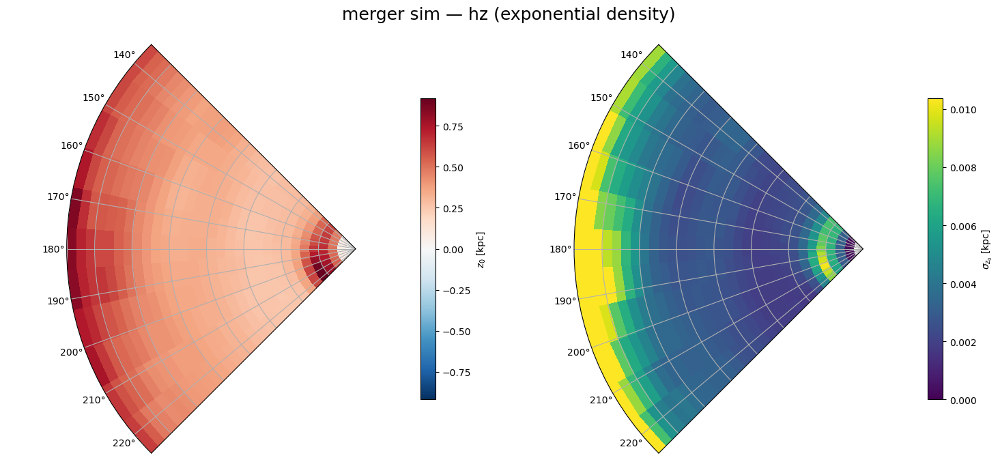

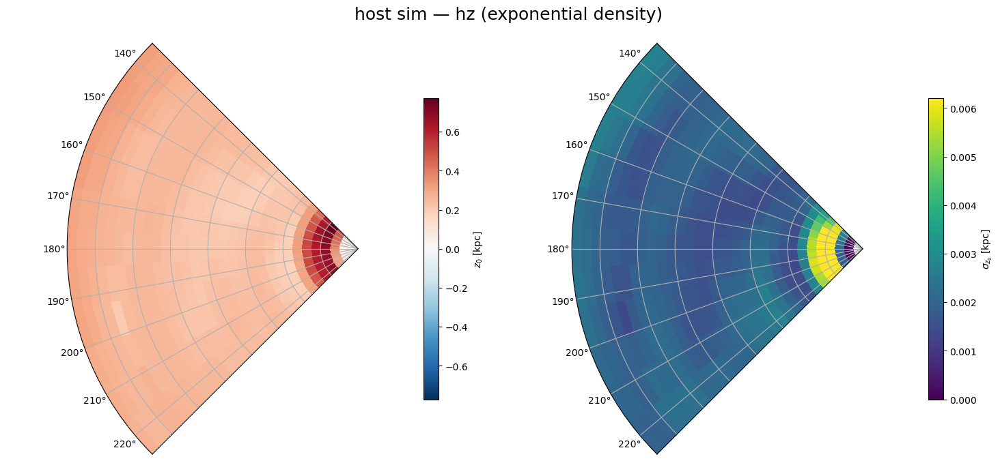

In [14]:
hz_grid_summary = {}

for name, d in prepared.items():
    n_R, n_seg = len(R_edges) - 1, len(d["SEG_PLOT_heat"])
    hz_med  = np.full((n_R, n_seg), np.nan)
    hz_std  = np.full((n_R, n_seg), np.nan)
    ok_grid = np.zeros((n_R, n_seg), dtype=bool)

    pairs = list(product(range(n_R), range(n_seg)))
    for k, (i_R, j_seg) in enumerate(pairs, 1):
        Rmin, Rmax = float(R_edges[i_R]), float(R_edges[i_R + 1])
        seg_id = d["SEG_PLOT_heat"][j_seg]
        z_binc_k, count_k, err_k, ns_k, ok_k = select_annulus_segment_density(
            d["R"], d["z"], d["segm"][seg_id], Rmin, Rmax,
            min_bin_count=min_bin_count, min_bins_for_fit=min_bins_for_fit,
            z_fit_min=z_fit_min, z_fit_max=z_fit_max, minN_total=minN_seg_total)
        if not ok_k:
            continue

        hz_val, hzerr, z0_val, z0err, fit_ok = fit_exp_density_curvefit(z_binc_k, count_k, err_k)
        if fit_ok:
            hz_med[i_R, j_seg] = hz_val
            hz_std[i_R, j_seg] = hzerr
            ok_grid[i_R, j_seg] = True

    print(f"{name} exponential hz fits complete:", int(ok_grid.sum()), "/", ok_grid.size)
    hz_grid_summary[name] = dict(hz_med=hz_med, hz_std=hz_std, ok_grid=ok_grid)

for name, d in prepared.items():
    zlim = float(np.nanmax(hz_grid_summary[name]["hz_med"]))  # auto-scale to this sim's max hz
    plot_z0_heatmap_sim(
        hz_grid_summary[name]["hz_med"], hz_grid_summary[name]["hz_std"],
        f"{name} sim — hz (exponential density)", d["crowd_bounds"], len(d["SEG_PLOT_heat"])
    )

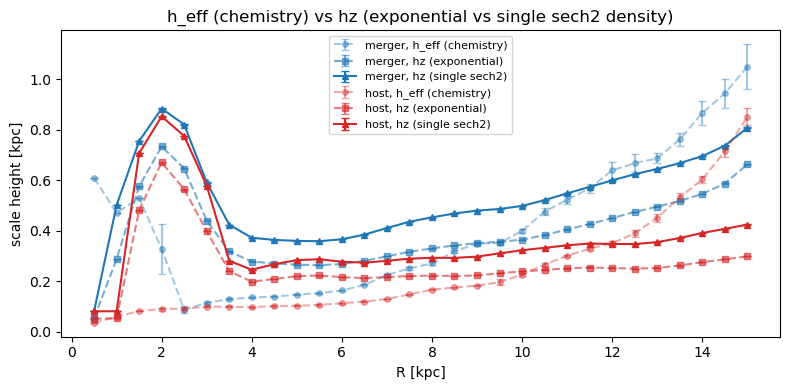

In [15]:
def sech2_density_single_np(z, A, hz, z0):
    dz = z - z0
    return A / np.cosh(dz / hz)**2

def fit_sech2_single_density_curvefit(z_binc, count, count_err):
    A_guess = max(count.max(), 1.0)
    p0 = [A_guess, 0.3, 0.0]
    bounds = ([0, 0.04, -0.5], [A_guess * 5, 3.0, 0.5])
    try:
        popt, pcov = curve_fit(sech2_density_single_np, z_binc, count, p0=p0, sigma=count_err,
                                absolute_sigma=True, bounds=bounds, maxfev=5000)
        hz_val, z0_val = popt[1], popt[2]
        hz_err = np.sqrt(pcov[1, 1]) if np.isfinite(pcov[1, 1]) else np.nan
        z0_err = np.sqrt(pcov[2, 2]) if np.isfinite(pcov[2, 2]) else np.nan
        return hz_val, hz_err, z0_val, z0_err, True
    except Exception:
        return np.nan, np.nan, np.nan, np.nan, False

hz_sech2_summary = {}

for name, d in prepared.items():
    in_wedge = np.zeros_like(d["R"], dtype=bool)
    for i in d["SEG_PLOT_heat"]:
        in_wedge |= d["segm"][i]

    R_w = d["R"][in_wedge]
    z_w = d["z"][in_wedge]

    hz_med = np.full(len(R_centers_flare), np.nan)
    hz_err = np.full(len(R_centers_flare), np.nan)

    for i_R, Rc in enumerate(R_centers_flare):
        Rmin, Rmax = Rc - R_width/2, Rc + R_width/2
        z_binc, count, count_err, n_stars, ok = select_R_bin_density(
            R_w, z_w, Rmin, Rmax,
            minN_total=minN_seg_total, min_bin_count=min_bin_count,
            min_bins_for_fit=min_bins_for_fit, z_fit_min=z_fit_min, z_fit_max=z_fit_max,
        )
        if not ok:
            continue
        hz_val, hzerr, z0_val, z0err, fit_ok = fit_sech2_single_density_curvefit(z_binc, count, count_err)
        if fit_ok:
            hz_med[i_R] = hz_val
            hz_err[i_R] = hzerr

    hz_sech2_summary[name] = dict(hz_med=hz_med, hz_err=hz_err)

fig, ax = plt.subplots(figsize=(8, 4))
sim_colors = {"merger": "C0", "host": "C3"}

for name in prepared:
    ax.errorbar(R_centers_flare, flare_summary[name]["h_eff_med"], yerr=flare_summary[name]["h_eff_std"],
                fmt="o--", ms=4, capsize=3, alpha=0.4, color=sim_colors[name], label=f"{name}, h_eff (chemistry)")
    ax.errorbar(R_centers_flare, hz_summary[name]["hz_med"], yerr=hz_summary[name]["hz_err"],
                fmt="s--", ms=4, capsize=3, alpha=0.6, color=sim_colors[name], label=f"{name}, hz (exponential)")
    ax.errorbar(R_centers_flare, hz_sech2_summary[name]["hz_med"], yerr=hz_sech2_summary[name]["hz_err"],
                fmt="^-", ms=4, capsize=3, color=sim_colors[name], label=f"{name}, hz (single sech2)")

ax.legend(fontsize=8)
ax.set_xlabel("R [kpc]")
ax.set_ylabel("scale height [kpc]")
ax.set_title("h_eff (chemistry) vs hz (exponential vs single sech2 density)")
plt.tight_layout()
plt.show()

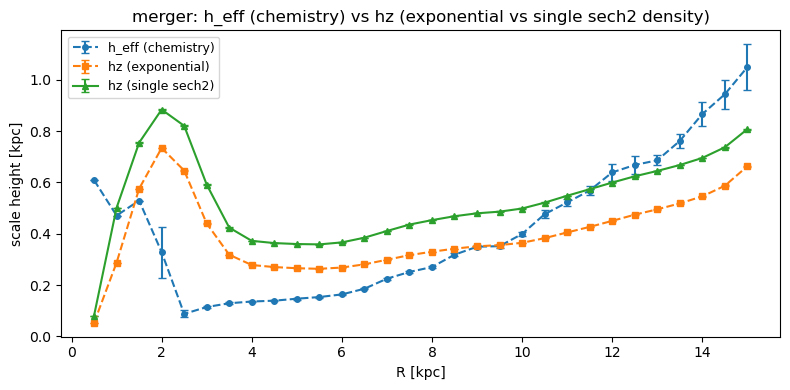

In [16]:
fig, ax = plt.subplots(figsize=(8, 4))

method_colors = {
    "chemistry": "C0",
    "exponential": "C1",
    "sech2": "C2",
}

name = "merger"

ax.errorbar(R_centers_flare, flare_summary[name]["h_eff_med"], yerr=flare_summary[name]["h_eff_std"],
            fmt="o--", ms=4, capsize=3, color=method_colors["chemistry"], label="h_eff (chemistry)")
ax.errorbar(R_centers_flare, hz_summary[name]["hz_med"], yerr=hz_summary[name]["hz_err"],
            fmt="s--", ms=4, capsize=3, color=method_colors["exponential"], label="hz (exponential)")
ax.errorbar(R_centers_flare, hz_sech2_summary[name]["hz_med"], yerr=hz_sech2_summary[name]["hz_err"],
            fmt="^-", ms=4, capsize=3, color=method_colors["sech2"], label="hz (single sech2)")

ax.legend(fontsize=9)
ax.set_xlabel("R [kpc]")
ax.set_ylabel("scale height [kpc]")
ax.set_title(f"{name}: h_eff (chemistry) vs hz (exponential vs single sech2 density)")
plt.tight_layout()
plt.show()

In [19]:
z0_chem_summary = {}

for name in prepared:
    z0_med = np.full(len(R_centers_flare), np.nan)
    z0_std = np.full(len(R_centers_flare), np.nan)

    for i_R, cell in per_R_flare[name].items():
        s = cell["samples"]["z0"]
        z0_med[i_R] = np.median(s)
        z0_std[i_R] = np.std(s)

    z0_chem_summary[name] = dict(z0_med=z0_med, z0_std=z0_std)

In [20]:
hz_summary = {}
z0_exp_summary = {}

for name, d in prepared.items():
    in_wedge = np.zeros_like(d["R"], dtype=bool)
    for i in d["SEG_PLOT_heat"]:
        in_wedge |= d["segm"][i]

    R_w = d["R"][in_wedge]
    z_w = d["z"][in_wedge]

    hz_med = np.full(len(R_centers_flare), np.nan)
    hz_err = np.full(len(R_centers_flare), np.nan)
    z0_med = np.full(len(R_centers_flare), np.nan)
    z0_err = np.full(len(R_centers_flare), np.nan)

    for i_R, Rc in enumerate(R_centers_flare):
        Rmin, Rmax = Rc - R_width/2, Rc + R_width/2
        z_binc, count, count_err, n_stars, ok = select_R_bin_density(
            R_w, z_w, Rmin, Rmax,
            minN_total=minN_seg_total, min_bin_count=min_bin_count,
            min_bins_for_fit=min_bins_for_fit, z_fit_min=z_fit_min, z_fit_max=z_fit_max,
        )
        if not ok:
            continue
        hz_val, hzerr, z0_val, z0err, fit_ok = fit_exp_density_curvefit(z_binc, count, count_err)
        if fit_ok:
            hz_med[i_R] = hz_val
            hz_err[i_R] = hzerr
            z0_med[i_R] = z0_val
            z0_err[i_R] = z0err

    hz_summary[name] = dict(hz_med=hz_med, hz_err=hz_err)
    z0_exp_summary[name] = dict(z0_med=z0_med, z0_err=z0_err)

In [21]:
hz_sech2_summary = {}
z0_sech2_summary = {}

for name, d in prepared.items():
    in_wedge = np.zeros_like(d["R"], dtype=bool)
    for i in d["SEG_PLOT_heat"]:
        in_wedge |= d["segm"][i]

    R_w = d["R"][in_wedge]
    z_w = d["z"][in_wedge]

    hz_med = np.full(len(R_centers_flare), np.nan)
    hz_err = np.full(len(R_centers_flare), np.nan)
    z0_med = np.full(len(R_centers_flare), np.nan)
    z0_err = np.full(len(R_centers_flare), np.nan)

    for i_R, Rc in enumerate(R_centers_flare):
        Rmin, Rmax = Rc - R_width/2, Rc + R_width/2
        z_binc, count, count_err, n_stars, ok = select_R_bin_density(
            R_w, z_w, Rmin, Rmax,
            minN_total=minN_seg_total, min_bin_count=min_bin_count,
            min_bins_for_fit=min_bins_for_fit, z_fit_min=z_fit_min, z_fit_max=z_fit_max,
        )
        if not ok:
            continue
        hz_val, hzerr, z0_val, z0err, fit_ok = fit_sech2_single_density_curvefit(z_binc, count, count_err)
        if fit_ok:
            hz_med[i_R] = hz_val
            hz_err[i_R] = hzerr
            z0_med[i_R] = z0_val
            z0_err[i_R] = z0err

    hz_sech2_summary[name] = dict(hz_med=hz_med, hz_err=hz_err)
    z0_sech2_summary[name] = dict(z0_med=z0_med, z0_err=z0_err)

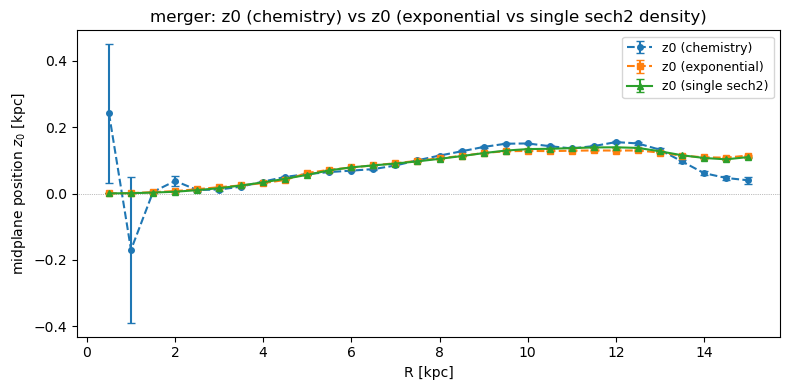

In [23]:
fig, ax = plt.subplots(figsize=(8, 4))

method_colors = {
    "chemistry": "C0",
    "exponential": "C1",
    "sech2": "C2",
}

name = "merger"

ax.errorbar(R_centers_flare, z0_chem_summary[name]["z0_med"], yerr=z0_chem_summary[name]["z0_std"],
            fmt="o--", ms=4, capsize=3, color=method_colors["chemistry"], label="z0 (chemistry)")
ax.errorbar(R_centers_flare, z0_exp_summary[name]["z0_med"], yerr=z0_exp_summary[name]["z0_err"],
            fmt="s--", ms=4, capsize=3, color=method_colors["exponential"], label="z0 (exponential)")
ax.errorbar(R_centers_flare, z0_sech2_summary[name]["z0_med"], yerr=z0_sech2_summary[name]["z0_err"],
            fmt="^-", ms=4, capsize=3, color=method_colors["sech2"], label="z0 (single sech2)")

ax.axhline(0, color='gray', lw=0.5, ls=':')
ax.legend(fontsize=9)
ax.set_xlabel("R [kpc]")
ax.set_ylabel("midplane position $z_0$ [kpc]")
ax.set_title(f"{name}: z0 (chemistry) vs z0 (exponential vs single sech2 density)")
plt.tight_layout()
plt.show()

## 2 component comparison

In [24]:
from scipy.optimize import brentq

def exp2_density_np(z, A1, A2, h1, d_h2, z0):
    h2 = h1 + d_h2
    dz = np.abs(z - z0)
    return A1 * np.exp(-dz / h1) + A2 * np.exp(-dz / h2)

def sech2_density_2comp_np(z, A1, A2, h1, d_h2, z0):
    h2 = h1 + d_h2
    dz = z - z0
    return A1 * (1 / np.cosh(dz / h1))**2 + A2 * (1 / np.cosh(dz / h2))**2

def h_eff_onesided(model_fn, popt, z0, A1, A2, z_max=8.0):
    """One-sided half-max crossing, matching mm.compute_h_eff_flare's definition."""
    half_max = 0.5 * (A1 + A2)
    def root_func(z):
        return model_fn(z, *popt) - half_max
    try:
        zstar = brentq(root_func, z0 + 1e-6, z0 + z_max)
        return zstar - z0
    except ValueError:
        return np.nan

def fit_2comp_curvefit(model_fn, z_binc, count, count_err):
    A0 = float(count.max())
    p0 = [0.7 * A0, 0.3 * A0, 0.2, 0.2, 0.0]
    bounds = ([0, 0, 0.01, 0.01, -1.5], [np.inf, np.inf, 3.0, 3.0, 1.5])
    try:
        popt, pcov = curve_fit(model_fn, z_binc, count, p0=p0, sigma=count_err,
                                bounds=bounds, maxfev=20000)
        A1, A2, h1, d_h2, z0_val = popt
        z0_err = np.sqrt(pcov[4, 4]) if np.isfinite(pcov[4, 4]) else np.nan
        heff_val = h_eff_onesided(model_fn, popt, z0_val, A1, A2)
        return heff_val, z0_val, z0_err, True
    except Exception:
        return np.nan, np.nan, np.nan, False

In [25]:
heff_exp2_summary = {}
z0_exp2_summary = {}

for name, d in prepared.items():
    in_wedge = np.zeros_like(d["R"], dtype=bool)
    for i in d["SEG_PLOT_heat"]:
        in_wedge |= d["segm"][i]

    R_w = d["R"][in_wedge]
    z_w = d["z"][in_wedge]

    heff_med = np.full(len(R_centers_flare), np.nan)
    z0_med = np.full(len(R_centers_flare), np.nan)
    z0_err = np.full(len(R_centers_flare), np.nan)

    for i_R, Rc in enumerate(R_centers_flare):
        Rmin, Rmax = Rc - R_width/2, Rc + R_width/2
        z_binc, count, count_err, n_stars, ok = select_R_bin_density(
            R_w, z_w, Rmin, Rmax,
            minN_total=minN_seg_total, min_bin_count=min_bin_count,
            min_bins_for_fit=min_bins_for_fit, z_fit_min=z_fit_min, z_fit_max=z_fit_max,
        )
        if not ok:
            continue
        heff_val, z0_val, z0e, fit_ok = fit_2comp_curvefit(exp2_density_np, z_binc, count, count_err)
        if fit_ok:
            heff_med[i_R] = heff_val
            z0_med[i_R] = z0_val
            z0_err[i_R] = z0e

    heff_exp2_summary[name] = dict(h_eff_med=heff_med)
    z0_exp2_summary[name] = dict(z0_med=z0_med, z0_err=z0_err)

In [26]:
heff_sech2_2_summary = {}
z0_sech2_2_summary = {}

for name, d in prepared.items():
    in_wedge = np.zeros_like(d["R"], dtype=bool)
    for i in d["SEG_PLOT_heat"]:
        in_wedge |= d["segm"][i]

    R_w = d["R"][in_wedge]
    z_w = d["z"][in_wedge]

    heff_med = np.full(len(R_centers_flare), np.nan)
    z0_med = np.full(len(R_centers_flare), np.nan)
    z0_err = np.full(len(R_centers_flare), np.nan)

    for i_R, Rc in enumerate(R_centers_flare):
        Rmin, Rmax = Rc - R_width/2, Rc + R_width/2
        z_binc, count, count_err, n_stars, ok = select_R_bin_density(
            R_w, z_w, Rmin, Rmax,
            minN_total=minN_seg_total, min_bin_count=min_bin_count,
            min_bins_for_fit=min_bins_for_fit, z_fit_min=z_fit_min, z_fit_max=z_fit_max,
        )
        if not ok:
            continue
        heff_val, z0_val, z0e, fit_ok = fit_2comp_curvefit(sech2_density_2comp_np, z_binc, count, count_err)
        if fit_ok:
            heff_med[i_R] = heff_val
            z0_med[i_R] = z0_val
            z0_err[i_R] = z0e

    heff_sech2_2_summary[name] = dict(h_eff_med=heff_med)
    z0_sech2_2_summary[name] = dict(z0_med=z0_med, z0_err=z0_err)

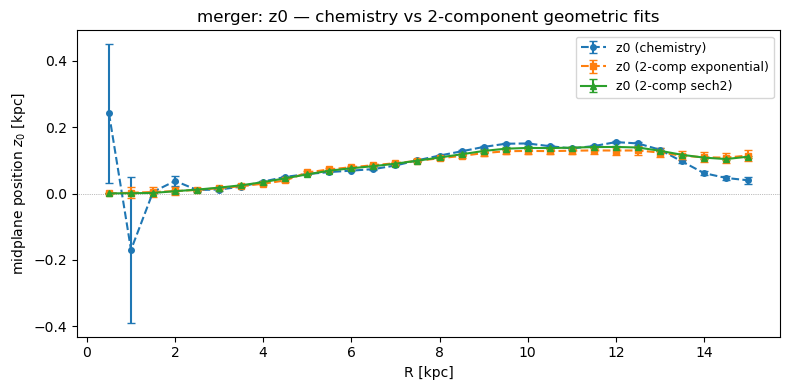

In [27]:
fig, ax = plt.subplots(figsize=(8, 4))
method_colors = {"chemistry": "C0", "exponential": "C1", "sech2": "C2"}
name = "merger"

ax.errorbar(R_centers_flare, z0_chem_summary[name]["z0_med"], yerr=z0_chem_summary[name]["z0_std"],
            fmt="o--", ms=4, capsize=3, color=method_colors["chemistry"], label="z0 (chemistry)")
ax.errorbar(R_centers_flare, z0_exp2_summary[name]["z0_med"], yerr=z0_exp2_summary[name]["z0_err"],
            fmt="s--", ms=4, capsize=3, color=method_colors["exponential"], label="z0 (2-comp exponential)")
ax.errorbar(R_centers_flare, z0_sech2_2_summary[name]["z0_med"], yerr=z0_sech2_2_summary[name]["z0_err"],
            fmt="^-", ms=4, capsize=3, color=method_colors["sech2"], label="z0 (2-comp sech2)")

ax.axhline(0, color='gray', lw=0.5, ls=':')
ax.legend(fontsize=9)
ax.set_xlabel("R [kpc]")
ax.set_ylabel("midplane position $z_0$ [kpc]")
ax.set_title(f"{name}: z0 — chemistry vs 2-component geometric fits")
plt.tight_layout()
plt.show()

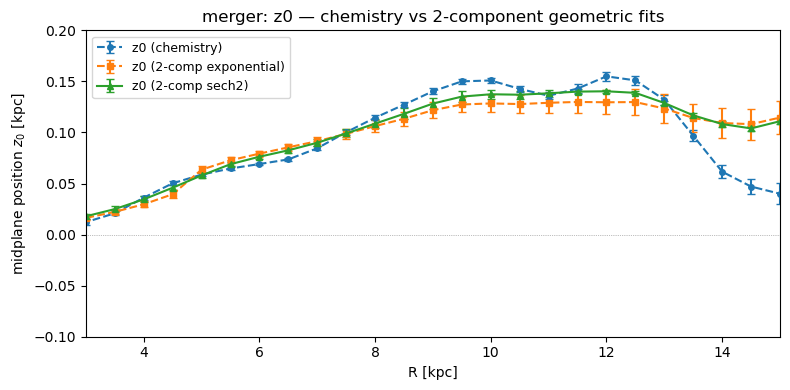

In [65]:
fig, ax = plt.subplots(figsize=(8, 4))
method_colors = {"chemistry": "C0", "exponential": "C1", "sech2": "C2"}
name = "merger"

ax.errorbar(R_centers_flare, z0_chem_summary[name]["z0_med"], yerr=z0_chem_summary[name]["z0_std"],
            fmt="o--", ms=4, capsize=3, color=method_colors["chemistry"], label="z0 (chemistry)")
ax.errorbar(R_centers_flare, z0_exp2_summary[name]["z0_med"], yerr=z0_exp2_summary[name]["z0_err"],
            fmt="s--", ms=4, capsize=3, color=method_colors["exponential"], label="z0 (2-comp exponential)")
ax.errorbar(R_centers_flare, z0_sech2_2_summary[name]["z0_med"], yerr=z0_sech2_2_summary[name]["z0_err"],
            fmt="^-", ms=4, capsize=3, color=method_colors["sech2"], label="z0 (2-comp sech2)")

ax.axhline(0, color='gray', lw=0.5, ls=':')
ax.legend(fontsize=9)
ax.set_xlabel("R [kpc]")
ax.set_ylabel("midplane position $z_0$ [kpc]")
ax.set_title(f"{name}: z0 — chemistry vs 2-component geometric fits")
ax.set_xlim(3,15)
ax.set_ylim(-0.1,0.2)
plt.tight_layout()
plt.show()

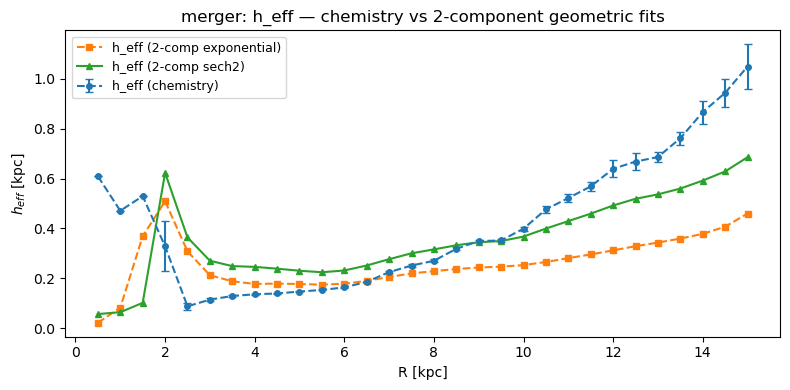

In [28]:
fig, ax = plt.subplots(figsize=(8, 4))

ax.errorbar(R_centers_flare, flare_summary[name]["h_eff_med"], yerr=flare_summary[name]["h_eff_std"],
            fmt="o--", ms=4, capsize=3, color=method_colors["chemistry"], label="h_eff (chemistry)")
ax.plot(R_centers_flare, heff_exp2_summary[name]["h_eff_med"], "s--",
        ms=4, color=method_colors["exponential"], label="h_eff (2-comp exponential)")
ax.plot(R_centers_flare, heff_sech2_2_summary[name]["h_eff_med"], "^-",
        ms=4, color=method_colors["sech2"], label="h_eff (2-comp sech2)")

ax.legend(fontsize=9)
ax.set_xlabel("R [kpc]")
ax.set_ylabel("$h_{eff}$ [kpc]")
ax.set_title(f"{name}: h_eff — chemistry vs 2-component geometric fits")
plt.tight_layout()
plt.show()

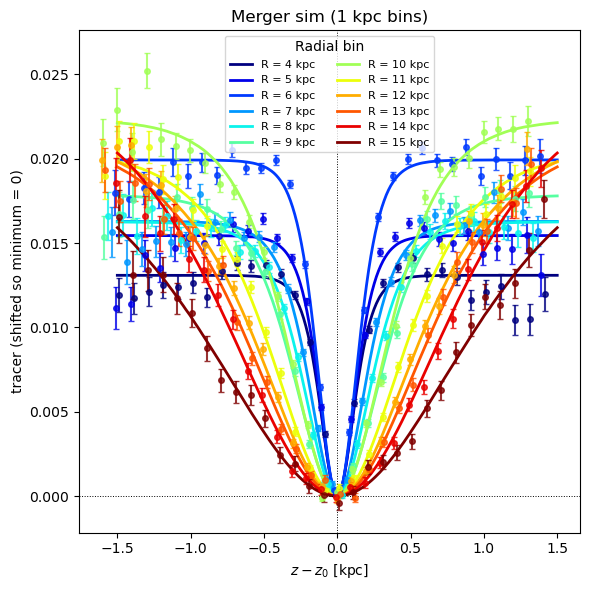

In [56]:
import matplotlib.pyplot as plt
import numpy as np

def plot_peak_aligned(per_R, R_centers, title, R_to_show=range(4, 16),
                      n_draws=200, cmap_name="jet", ax=None, drop=None):
    # integer-kpc centers only (the grid is spaced 0.5 kpc, so this avoids near-duplicate bins)
    idx = sorted(
        [i_R for i_R in per_R
         if np.isclose(R_centers[i_R] % 1, 0) and int(round(R_centers[i_R])) in R_to_show],
        key=lambda i_R: R_centers[i_R],
    )
    cmap = plt.get_cmap(cmap_name, len(idx))
    z_grid = np.linspace(-1.5, 1.5, 400)
    rng = np.random.default_rng(0)

    if ax is None:
        fig, ax = plt.subplots(figsize=(6, 6))

    for k, i_R in enumerate(idx):
        cell = per_R[i_R]
        s = cell["samples"]
        n_avail = len(s["z0"])
        draw_idx = rng.choice(n_avail, size=min(n_draws, n_avail), replace=False)

        curves = []
        for i in draw_idx:
            A1, A2 = s["A1"][i], s["A2"][i]
            h1 = s["h1"][i]
            h2 = h1 + s["d_h2"][i]
            z0 = s["z0"][i]
            peak = A1 + A2                      # value of the model at its minimum, relative to offset
            curves.append(mm.mixture_of_sech2(z_grid + z0, A1, A2, h1, h2, z0) - peak)
        model_dz = np.median(curves, axis=0)

        dz_data = cell["z_binc"] - np.median(s["z0"])
        shift = np.median(cell["mean"] - np.interp(dz_data, z_grid, model_dz))
        dy_data = cell["mean"] - shift

        ax.plot(z_grid, model_dz, "-", color=cmap(k), lw=2,
                label=f"R = {R_centers[i_R]:.0f} kpc")
        ax.errorbar(dz_data, dy_data, yerr=cell["err"], fmt="o",
                    color=cmap(k), ms=4, capsize=2, alpha=0.8)

    ax.axhline(0, color="k", lw=0.7, ls=":")
    ax.axvline(0, color="k", lw=0.7, ls=":")
    if drop is not None:                         # optional: fixed height above the trough
        ax.axhline(drop, color="r", lw=1, ls="--", label=f"DROP = {drop}")
    ax.set_xlabel(r"$z - z_0$ [kpc]")
    ax.set_ylabel("tracer (shifted so minimum = 0)")
    ax.set_title(title)
    ax.legend(title="Radial bin", fontsize=8, ncol=2)
    return ax

fig, ax = plt.subplots(figsize=(6, 6))
plot_peak_aligned(per_R_flare["merger"], R_centers_flare, "Merger sim (1 kpc bins)",
                  R_to_show=range(4, 16), ax=ax)
plt.tight_layout()
plt.show()

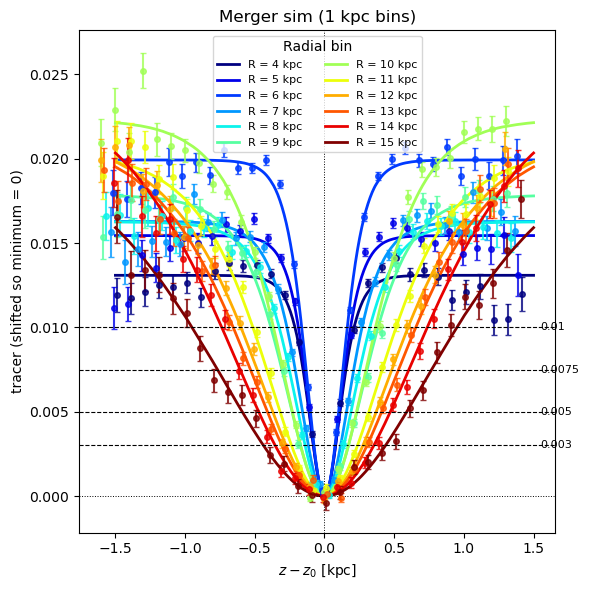

R   drop=0.003    drop=0.005    drop=0.0075   drop=0.01   
  4  0.079         0.110         0.153         0.211       
  5  0.079         0.107         0.144         0.187       
  6  0.076         0.102         0.132         0.163       
  7  0.116         0.157         0.209         0.268       
  8  0.139         0.190         0.254         0.326       
  9  0.172         0.233         0.306         0.385       
 10  0.172         0.230         0.298         0.366       
 11  0.236         0.318         0.414         0.513       
 12  0.275         0.371         0.483         0.599       
 13  0.305         0.410         0.530         0.653       
 14  0.354         0.473         0.606         0.738       
 15  0.438         0.591         0.770         0.950       


In [57]:
from scipy.optimize import brentq

DROPS = [0.003, 0.005, 0.0075, 0.01]

fig, ax = plt.subplots(figsize=(6, 6))
plot_peak_aligned(per_R_flare["merger"], R_centers_flare, "Merger sim (1 kpc bins)",
                  R_to_show=range(4, 16), ax=ax)
for d in DROPS:
    ax.axhline(d, color="k", lw=0.8, ls="--")
    ax.text(1.55, d, f"{d}", va="center", fontsize=8)
plt.tight_layout(); plt.show()

# crossing height (one-sided, z - z0 > 0) for each bin and level
z_grid = np.linspace(0, 1.5, 600)
per_R = per_R_flare["merger"]
print("R   " + "  ".join(f"drop={d:<7}" for d in DROPS))
for i_R in sorted(per_R, key=lambda i: R_centers_flare[i]):
    Rc = R_centers_flare[i_R]
    if not (np.isclose(Rc % 1, 0) and 4 <= Rc <= 15):
        continue
    s = per_R[i_R]["samples"]
    curves = np.array([
        mm.mixture_of_sech2(z_grid + s["z0"][i], s["A1"][i], s["A2"][i],
                            s["h1"][i], s["h1"][i] + s["d_h2"][i], s["z0"][i])
        - (s["A1"][i] + s["A2"][i])
        for i in range(0, len(s["z0"]), max(1, len(s["z0"]) // 200))
    ])
    med = np.median(curves, axis=0)
    out = []
    for d in DROPS:
        try:
            out.append(f"{brentq(lambda z: np.interp(z, z_grid, med) - d, 0, 1.5):.3f}")
        except ValueError:
            out.append("  nan ")
    print(f"{Rc:>3.0f}  " + "  ".join(f"{v:<12}" for v in out))

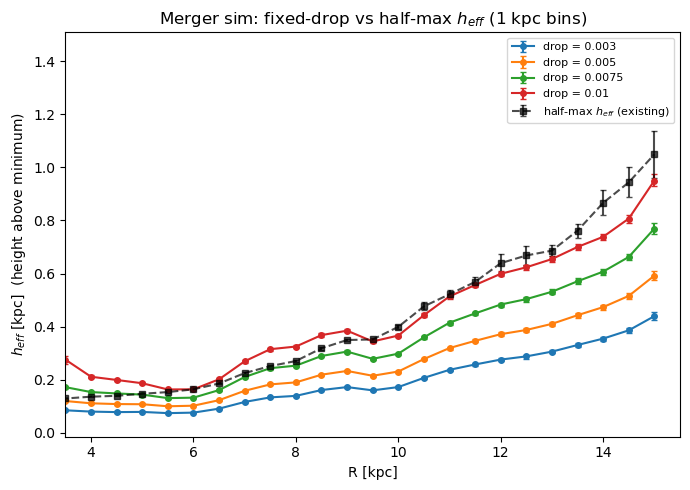

In [58]:
DROPS = [0.003, 0.005, 0.0075, 0.01]
z_grid = np.linspace(0, 2.0, 800)
per_R = per_R_flare["merger"]

def crossing_heights(s, drop, n_max=500):
    """h at which the peak-subtracted curve first rises to `drop`, one value per posterior draw."""
    step = max(1, len(s["z0"]) // n_max)
    out = []
    for i in range(0, len(s["z0"]), step):
        A1, A2, h1 = s["A1"][i], s["A2"][i], s["h1"][i]
        h2 = h1 + s["d_h2"][i]
        c = mm.mixture_of_sech2(z_grid + s["z0"][i], A1, A2, h1, h2, s["z0"][i]) - (A1 + A2)
        j = np.argmax(c >= drop)
        if c[j] < drop or j == 0:            # never reached within z_grid
            out.append(np.nan)
        else:                                 # linear interpolation between grid points
            out.append(np.interp(drop, [c[j-1], c[j]], [z_grid[j-1], z_grid[j]]))
    return np.array(out)

idx_all = sorted(per_R, key=lambda i: R_centers_flare[i])
Rs = np.array([R_centers_flare[i] for i in idx_all])

heff_drop = {}
for d in DROPS:
    med, lo, hi = [], [], []
    for i_R in idx_all:
        h = crossing_heights(per_R[i_R]["samples"], d)
        if np.isfinite(h).sum() < 0.5 * len(h):      # require most draws to reach the level
            med.append(np.nan); lo.append(np.nan); hi.append(np.nan)
        else:
            p16, p50, p84 = np.nanpercentile(h, [16, 50, 84])
            med.append(p50); lo.append(p50 - p16); hi.append(p84 - p50)
    heff_drop[d] = (np.array(med), np.array(lo), np.array(hi))

fig, ax = plt.subplots(figsize=(7, 5))
for k, d in enumerate(DROPS):
    med, lo, hi = heff_drop[d]
    ax.errorbar(Rs, med, yerr=[lo, hi], fmt="o-", ms=4, capsize=2, color=f"C{k}",
                label=f"drop = {d}")

# existing half-max h_eff for comparison
hm = flare_summary["merger"]
ax.errorbar(R_centers_flare, hm["h_eff_med"], yerr=hm["h_eff_std"], fmt="s--",
            color="k", ms=4, capsize=2, alpha=0.7, label="half-max $h_{eff}$ (existing)")

ax.set_xlim(3.5, 15.5)
ax.set_xlabel("R [kpc]")
ax.set_ylabel(r"$h_{eff}$ [kpc]  (height above minimum)")
ax.set_title("Merger sim: fixed-drop vs half-max $h_{eff}$ (1 kpc bins)")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## age bins

In [45]:
for name, df in sims.items():
    print(name, "age range:", df["age"].min(), "-", df["age"].max())

merger age range: 12.690577831986584 - 23.529343998346736
host age range: 2.881236929472632 - 7.441591043637734


In [46]:
import pandas as pd
import numpy as np

df_merger = pd.read_csv("sim_disc_merger(1).csv")
print("age range:", df_merger["age"].min(), "-", df_merger["age"].max())

age range: -0.5225345329479971 - 10.316231633412157


In [47]:
AGE_BINS = {
    "0-3": (0, 3),
    "3-8": (3, 8),
    "8+": (8, np.inf),
}

prepared_by_age = {}

R_all = df_merger["R"].to_numpy()
z_all = df_merger["z"].to_numpy()
phi_all = df_merger["phi"].to_numpy()
tracer_all = df_merger["ofe"].to_numpy()
age_all = df_merger["age"].to_numpy()

for age_label, (age_lo, age_hi) in AGE_BINS.items():
    finite = (np.isfinite(R_all) & np.isfinite(z_all) & np.isfinite(phi_all)
              & np.isfinite(tracer_all) & np.isfinite(age_all))
    age_mask = (age_all >= age_lo) & (age_all < age_hi)
    keep = finite & age_mask & (R_all < 16.0)

    R = R_all[keep]; z = z_all[keep]; phi = phi_all[keep]; tracer = tracer_all[keep]
    tracer_err = np.full_like(tracer, OFE_ERR_PLACEHOLDER, dtype=float)

    segm, crowd_bounds, window_edges, seg_diag = build_segment_setup(
        phi, phi0=phi0, crowd_halfwidth_deg=45, n_crowd=11
    )
    SEG_PLOT_heat = list(range(1, seg_diag["n_crowd"] + 1))

    prepared_by_age[age_label] = dict(
        R=R, z=z, phi=phi, tracer=tracer, tracer_err=tracer_err,
        segm=segm, crowd_bounds=crowd_bounds, window_edges=window_edges,
        SEG_PLOT_heat=SEG_PLOT_heat,
    )
    print(f"merger [{age_label} Gyr]: {len(R)} stars")

merger [0-3 Gyr]: 3303130 stars
merger [3-8 Gyr]: 17082629 stars
merger [8+ Gyr]: 19046056 stars


In [59]:
per_cell_z0_age = {}
z0_summary_age = {}

for age_label, d in prepared_by_age.items():
    seg_masks_fit = {i: d["segm"][i] for i in d["SEG_PLOT_heat"]}

    per_cell_z0_age[age_label] = mm.run_grid_fit(
        d["R"], d["z"], d["tracer"], d["tracer_err"],
        seg_masks_fit, R_edges,
        model_fn=mm.model_z0,
        label=f"merger_{age_label}_z0",
        results_path=f"sim_grid_fit_z0_merger_{age_label}.pkl",
        minN_total=minN_seg_total,
        min_bin_count=min_bin_count,
        min_bins_for_fit=min_bins_for_fit,
        z_fit_min=z_fit_min, z_fit_max=z_fit_max,
    )

    z0_med, z0_std, _, _ = mm.summarize_grid_fit(
        per_cell_z0_age[age_label], n_R=len(R_edges) - 1, n_seg=len(seg_masks_fit)
    )
    z0_summary_age[age_label] = dict(z0_med=z0_med, z0_std=z0_std)

[merger_0-3_z0] grid fit:   0%|                         | 0/330 [00:00<?, ?it/s]/Users/emmatasso/outerdisk/midplane_model.py:194: RuntimeWarning: invalid value encountered in divide
  mean_tracer = stat1.statistic / stat2.statistic
/Users/emmatasso/outerdisk/midplane_model.py:195: RuntimeWarning: divide by zero encountered in divide
  mean_tracer_err = np.sqrt(1 / stat2.statistic + intrinsic_scatter ** 2)
[merger_0-3_z0] grid fit:  37%|█████▌         | 123/330 [00:02<00:03, 54.49it/s]/Users/emmatasso/outerdisk/midplane_model.py:206: UserWarning: There are not enough devices to run parallel chains: expected 2 but got 1. Chains will be drawn sequentially. If you are running MCMC in CPU, consider using `numpyro.set_host_device_count(2)` at the beginning of your program. You can double-check how many devices are available in your system using `jax.local_device_count()`.
  sampler = infer.MCMC(
[merger_0-3_z0] grid fit:  42%|██████▎        | 140/330 [02:15<03:03,  1.04it/s]


KeyboardInterrupt: 

In [ ]:
for age_label, d in prepared_by_age.items():
    plot_z0_heatmap_sim(
        z0_summary_age[age_label]["z0_med"], z0_summary_age[age_label]["z0_std"],
        f"merger sim, age {age_label} Gyr — z0", d["crowd_bounds"], len(d["SEG_PLOT_heat"])
    )

In [ ]:
for age_label, d in prepared_by_age.items():
    print(f"age {age_label} Gyr: {len(d['R']):,} stars")

In [30]:
import numpy as np

age_label = "8+"   # change to inspect other bins
z0_grid = z0_summary_age[age_label]["z0_med"]
z0_err_grid = z0_summary_age[age_label]["z0_std"]

# flatten and sort by |z0| to find the most extreme (bluest/reddest) cells
flat_idx = np.argsort(-np.abs(np.nan_to_num(z0_grid, nan=-np.inf)).ravel())
n_R, n_seg = z0_grid.shape

print(f"Most extreme z0 cells in {age_label} Gyr bin:")
for idx in flat_idx[:15]:
    i_R, j_seg = np.unravel_index(idx, z0_grid.shape)
    val = z0_grid[i_R, j_seg]
    if np.isfinite(val):
        print(f"  (i_R={i_R}, j_seg={j_seg})  R=[{R_edges[i_R]:.1f},{R_edges[i_R+1]:.1f}]  "
              f"z0={val:+.3f} ± {z0_err_grid[i_R,j_seg]:.3f}")

Most extreme z0 cells in 8+ Gyr bin:
  (i_R=21, j_seg=2)  R=[11.0,11.5]  z0=+1.264 ± 0.049
  (i_R=22, j_seg=5)  R=[11.5,12.0]  z0=+1.247 ± 0.823
  (i_R=15, j_seg=2)  R=[8.0,8.5]  z0=-1.237 ± 0.061
  (i_R=20, j_seg=4)  R=[10.5,11.0]  z0=-1.193 ± 0.075
  (i_R=22, j_seg=6)  R=[11.5,12.0]  z0=+1.180 ± 0.793
  (i_R=20, j_seg=3)  R=[10.5,11.0]  z0=+1.177 ± 0.066
  (i_R=18, j_seg=3)  R=[9.5,10.0]  z0=+1.161 ± 0.074
  (i_R=22, j_seg=10)  R=[11.5,12.0]  z0=-1.159 ± 0.063
  (i_R=23, j_seg=0)  R=[12.0,12.5]  z0=+1.144 ± 0.051
  (i_R=20, j_seg=5)  R=[10.5,11.0]  z0=+1.138 ± 0.075
  (i_R=18, j_seg=1)  R=[9.5,10.0]  z0=-1.138 ± 0.060
  (i_R=17, j_seg=4)  R=[9.0,9.5]  z0=-1.136 ± 0.053
  (i_R=19, j_seg=5)  R=[10.0,10.5]  z0=+1.132 ± 0.041
  (i_R=20, j_seg=0)  R=[10.5,11.0]  z0=-1.109 ± 0.103
  (i_R=22, j_seg=4)  R=[11.5,12.0]  z0=+1.106 ± 0.091


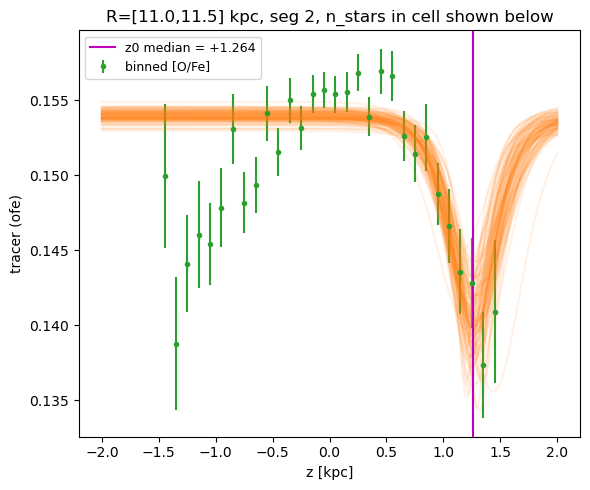

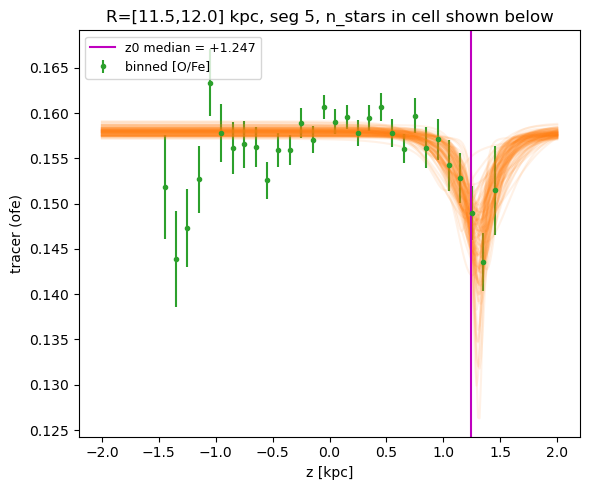

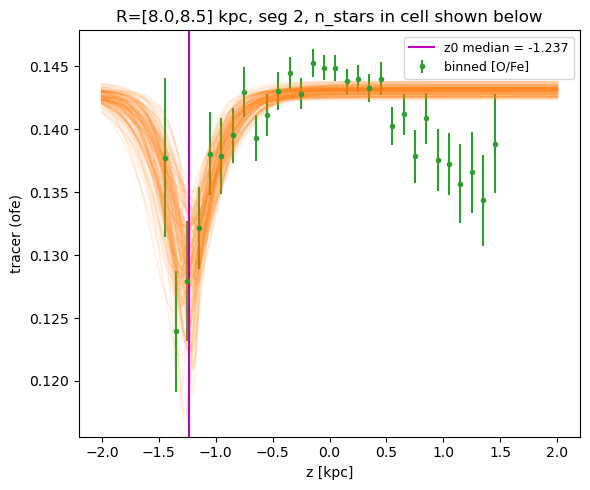

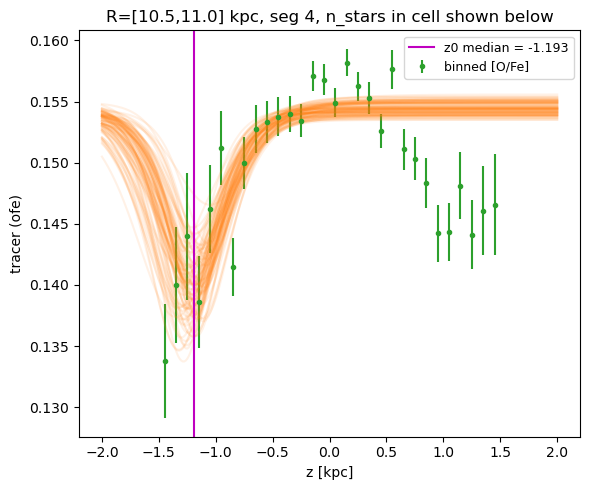

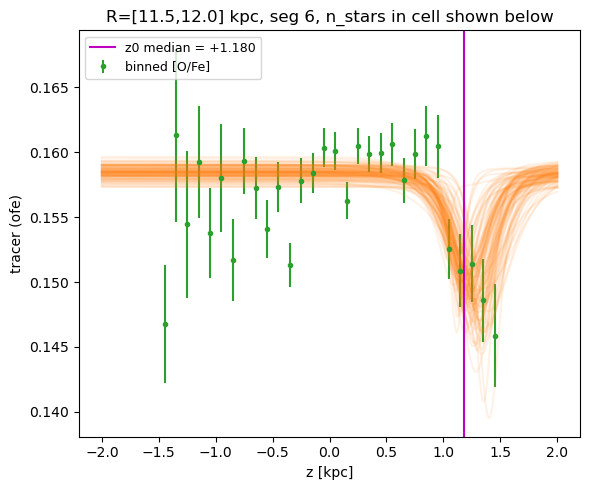

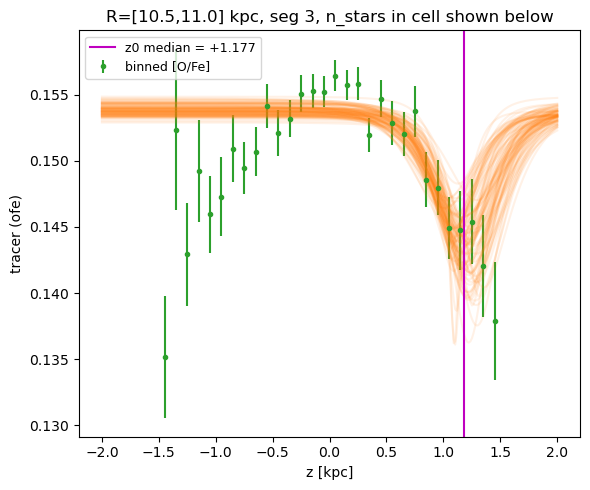

In [31]:
import matplotlib.pyplot as plt

def plot_cell_fit(per_cell, i_R, j_seg, R_edges, title_extra=""):
    cell = per_cell.get((i_R, j_seg))
    if cell is None:
        print(f"no cell data for (i_R={i_R}, j_seg={j_seg})")
        return

    s = cell["samples"]
    z_grid = np.linspace(-2, 2, 300)

    fig, ax = plt.subplots(figsize=(6, 5))
    ax.errorbar(cell["z_binc"], cell["mean"], yerr=cell["err"],
                color="C2", linestyle="", marker=".", label="binned [O/Fe]")

    for i in range(min(100, len(s["A1"]))):
        cs = {k: v[i] for k, v in s.items()}
        cs["h2"] = cs["h1"] + cs["d_h2"]
        y_pred = mm.mixture_of_sech2(z_grid, cs["A1"], cs["A2"], cs["h1"], cs["h2"], cs["z0"]) + cs["offset"]
        ax.plot(z_grid, y_pred, color="C1", alpha=0.1)

    ax.axvline(np.median(s["z0"]), color="m", ls="-", lw=1.5, label=f"z0 median = {np.median(s['z0']):+.3f}")
    ax.set_xlabel("z [kpc]")
    ax.set_ylabel("tracer (ofe)")
    ax.set_title(f"R=[{R_edges[i_R]:.1f},{R_edges[i_R+1]:.1f}] kpc, seg {j_seg}{title_extra}")
    ax.legend(fontsize=9)
    plt.tight_layout()
    plt.show()

# plot the top few extreme cells from Step 1
for idx in flat_idx[:6]:
    i_R, j_seg = np.unravel_index(idx, z0_grid.shape)
    if np.isfinite(z0_grid[i_R, j_seg]):
        plot_cell_fit(per_cell_z0_age[age_label], i_R, j_seg, R_edges,
                      title_extra=f", n_stars in cell shown below")

In [33]:
for idx in flat_idx[:15]:
    i_R, j_seg = np.unravel_index(idx, z0_grid.shape)
    if not np.isfinite(z0_grid[i_R, j_seg]):
        continue
    d = prepared_by_age[age_label]
    seg_id = d["SEG_PLOT_heat"][j_seg]
    Rmin, Rmax = R_edges[i_R], R_edges[i_R+1]
    m = d["segm"][seg_id] & (d["R"] >= Rmin) & (d["R"] < Rmax)
    n_stars = int(m.sum())
    print(f"R=[{Rmin:.1f},{Rmax:.1f}] seg={seg_id}: z0={z0_grid[i_R,j_seg]:+.3f}±{z0_err_grid[i_R,j_seg]:.3f}, n_stars={n_stars}")

R=[11.0,11.5] seg=3: z0=+1.264±0.049, n_stars=10881
R=[11.5,12.0] seg=6: z0=+1.247±0.823, n_stars=9691
R=[8.0,8.5] seg=3: z0=-1.237±0.061, n_stars=10742
R=[10.5,11.0] seg=5: z0=-1.193±0.075, n_stars=11415
R=[11.5,12.0] seg=7: z0=+1.180±0.793, n_stars=9462
R=[10.5,11.0] seg=4: z0=+1.177±0.066, n_stars=11477
R=[9.5,10.0] seg=4: z0=+1.161±0.074, n_stars=11364
R=[11.5,12.0] seg=11: z0=-1.159±0.063, n_stars=8847
R=[12.0,12.5] seg=1: z0=+1.144±0.051, n_stars=9457
R=[10.5,11.0] seg=6: z0=+1.138±0.075, n_stars=11163
R=[9.5,10.0] seg=2: z0=-1.138±0.060, n_stars=10806
R=[9.0,9.5] seg=5: z0=-1.136±0.053, n_stars=10984
R=[10.0,10.5] seg=6: z0=+1.132±0.041, n_stars=11234
R=[10.5,11.0] seg=1: z0=-1.109±0.103, n_stars=11263
R=[11.5,12.0] seg=5: z0=+1.106±0.091, n_stars=9912


In [34]:
# candidate "boring" cells: same age bin, similar outer-R range, but small |z0| and tight error
mask_finite = np.isfinite(z0_grid) & np.isfinite(z0_err_grid)
i_Rs, j_segs = np.where(mask_finite)

candidates = []
for i_R, j_seg in zip(i_Rs, j_segs):
    Rmin, Rmax = R_edges[i_R], R_edges[i_R+1]
    if not (8.0 <= Rmin <= 12.0):   # same outer-disk range as the extreme cells above
        continue
    val = z0_grid[i_R, j_seg]
    err = z0_err_grid[i_R, j_seg]
    candidates.append((abs(val), err, i_R, j_seg, val))

# sort by smallest |z0| first -- these are the "boring", presumably well-behaved cells
candidates.sort(key=lambda x: x[0])

print("Well-behaved cells for comparison (same R range, small |z0|):")
for absval, err, i_R, j_seg, val in candidates[:10]:
    seg_id = d["SEG_PLOT_heat"][j_seg]
    Rmin, Rmax = R_edges[i_R], R_edges[i_R+1]
    m = d["segm"][seg_id] & (d["R"] >= Rmin) & (d["R"] < Rmax)
    n_stars = int(m.sum())
    print(f"  R=[{Rmin:.1f},{Rmax:.1f}] seg={seg_id}: z0={val:+.3f}±{err:.3f}, n_stars={n_stars}")

Well-behaved cells for comparison (same R range, small |z0|):
  R=[11.0,11.5] seg=7: z0=-0.028±0.327, n_stars=10463
  R=[11.5,12.0] seg=8: z0=-0.032±0.257, n_stars=9511
  R=[12.0,12.5] seg=4: z0=+0.061±0.247, n_stars=8914
  R=[10.5,11.0] seg=7: z0=-0.104±0.283, n_stars=10745
  R=[12.0,12.5] seg=2: z0=-0.107±0.303, n_stars=9725
  R=[12.0,12.5] seg=6: z0=-0.111±0.252, n_stars=8029
  R=[12.0,12.5] seg=8: z0=-0.133±0.332, n_stars=8579
  R=[9.5,10.0] seg=7: z0=-0.179±0.682, n_stars=11189
  R=[12.0,12.5] seg=7: z0=-0.183±0.228, n_stars=8217
  R=[12.0,12.5] seg=11: z0=-0.194±0.420, n_stars=8414


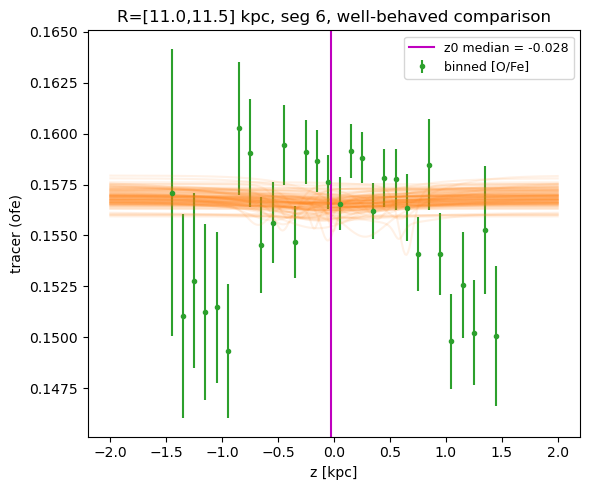

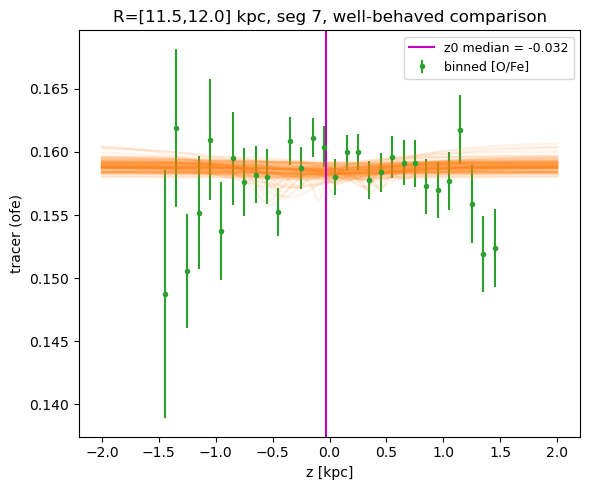

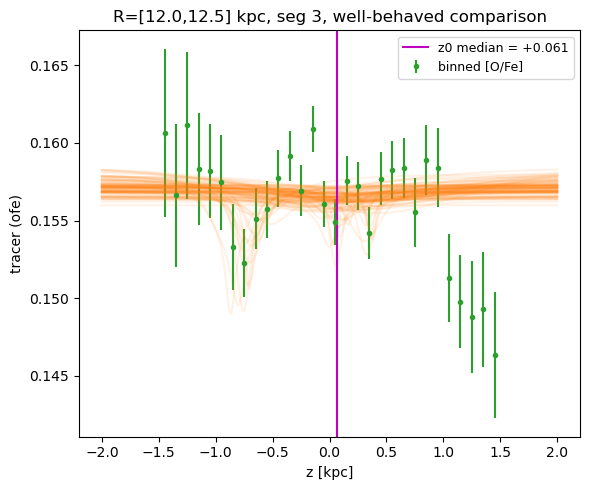

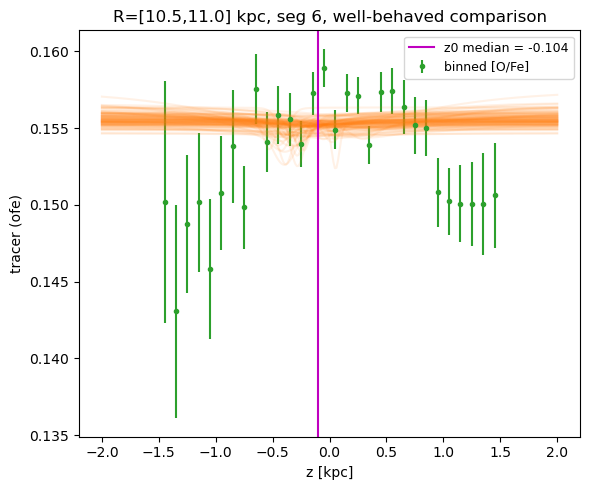

In [35]:
for absval, err, i_R, j_seg, val in candidates[:4]:
    plot_cell_fit(per_cell_z0_age[age_label], i_R, j_seg, R_edges,
                  title_extra=", well-behaved comparison")

In [38]:
for age_label in ["0-3", "3-8", "8+"]:
    z0_grid = z0_summary_age[age_label]["z0_med"]
    z0_err_grid = z0_summary_age[age_label]["z0_std"]
    d = prepared_by_age[age_label]

    finite_mask = np.isfinite(z0_grid)
    i_Rs, j_segs = np.where(finite_mask)
    vals = z0_grid[finite_mask]

    order = np.argsort(-np.abs(vals))  # descending by |z0|, finite values only

    print(f"\n=== {age_label} Gyr: most extreme z0 cells ({finite_mask.sum()} finite cells total) ===")
    for k in order[:8]:
        i_R, j_seg = i_Rs[k], j_segs[k]
        val = z0_grid[i_R, j_seg]
        seg_id = d["SEG_PLOT_heat"][j_seg]
        Rmin, Rmax = R_edges[i_R], R_edges[i_R+1]
        m = d["segm"][seg_id] & (d["R"] >= Rmin) & (d["R"] < Rmax)
        n_stars = int(m.sum())
        print(f"  R=[{Rmin:.1f},{Rmax:.1f}] seg={seg_id}: z0={val:+.3f}±{z0_err_grid[i_R,j_seg]:.3f}, n_stars={n_stars}")


=== 0-3 Gyr: most extreme z0 cells (197 finite cells total) ===
  R=[12.5,13.0] seg=1: z0=-0.936±0.024, n_stars=3836
  R=[15.0,15.5] seg=9: z0=-0.726±0.114, n_stars=1438
  R=[15.0,15.5] seg=7: z0=-0.485±0.096, n_stars=1678
  R=[15.0,15.5] seg=6: z0=-0.483±0.076, n_stars=2050
  R=[14.5,15.0] seg=7: z0=-0.458±0.038, n_stars=1701
  R=[15.0,15.5] seg=8: z0=-0.411±0.094, n_stars=1607
  R=[14.5,15.0] seg=9: z0=-0.409±0.036, n_stars=1947
  R=[14.0,14.5] seg=7: z0=-0.406±0.047, n_stars=1723

=== 3-8 Gyr: most extreme z0 cells (330 finite cells total) ===
  R=[13.5,14.0] seg=2: z0=+0.482±0.259, n_stars=6136
  R=[3.0,3.5] seg=8: z0=+0.415±0.272, n_stars=6498
  R=[3.0,3.5] seg=3: z0=-0.410±0.160, n_stars=4370
  R=[13.0,13.5] seg=9: z0=+0.399±0.094, n_stars=5559
  R=[2.5,3.0] seg=2: z0=-0.384±0.151, n_stars=3306
  R=[15.0,15.5] seg=4: z0=-0.361±0.112, n_stars=3315
  R=[9.5,10.0] seg=8: z0=+0.306±0.103, n_stars=7637
  R=[9.5,10.0] seg=7: z0=+0.297±0.113, n_stars=7877

=== 8+ Gyr: most extreme z0 c

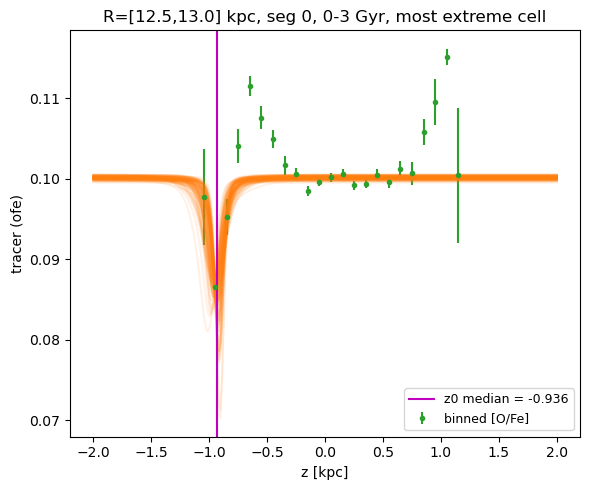

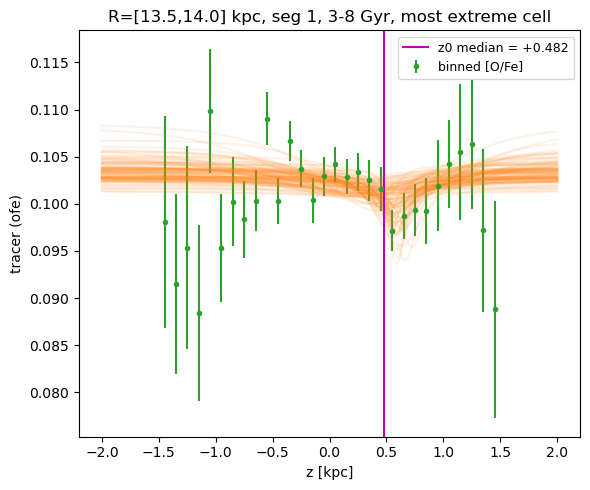

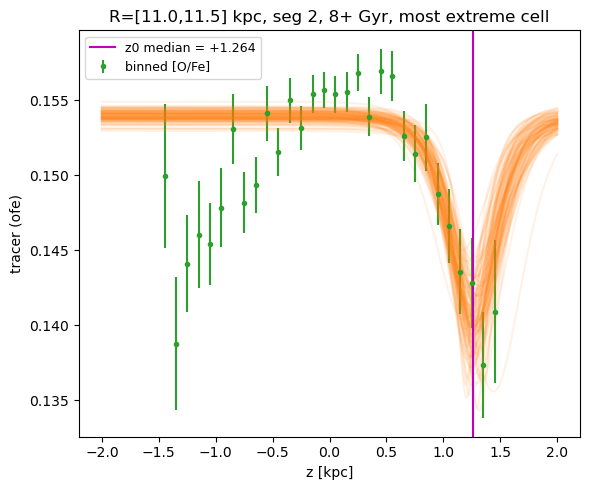

In [39]:
for age_label in ["0-3", "3-8", "8+"]:
    z0_grid = z0_summary_age[age_label]["z0_med"]
    finite_mask = np.isfinite(z0_grid)
    i_Rs, j_segs = np.where(finite_mask)
    vals = z0_grid[finite_mask]
    order = np.argsort(-np.abs(vals))

    if len(order) == 0:
        print(f"{age_label}: no finite cells at all")
        continue

    i_R, j_seg = i_Rs[order[0]], j_segs[order[0]]
    plot_cell_fit(per_cell_z0_age[age_label], i_R, j_seg, R_edges,
                  title_extra=f", {age_label} Gyr, most extreme cell")

In [40]:
R_sun = 8.275

for age_label in ["0-3", "3-8"]:
    d = prepared_by_age[age_label]
    theta_edges = np.unwrap(np.array(d["crowd_bounds"], float))
    for i in range(1, len(theta_edges)):
        while theta_edges[i] <= theta_edges[i - 1]:
            theta_edges[i] += 2 * np.pi

    j_seg_focus = None
    for idx, seg_id in enumerate(d["SEG_PLOT_heat"]):
        a, b = theta_edges[idx], theta_edges[idx + 1]
        if between_ccw(np.array([phi0]), a, b)[0]:
            j_seg_focus = idx
            seg_id_focus = seg_id
            break

    i_R_focus = np.searchsorted(R_edges, R_sun) - 1

    print(f"{age_label} Gyr: solar-neighborhood cell -> seg index {j_seg_focus} (id {seg_id_focus}), "
          f"R bin [{R_edges[i_R_focus]:.1f},{R_edges[i_R_focus+1]:.1f}]")

0-3 Gyr: solar-neighborhood cell -> seg index 5 (id 6), R bin [8.0,8.5]
3-8 Gyr: solar-neighborhood cell -> seg index 5 (id 6), R bin [8.0,8.5]


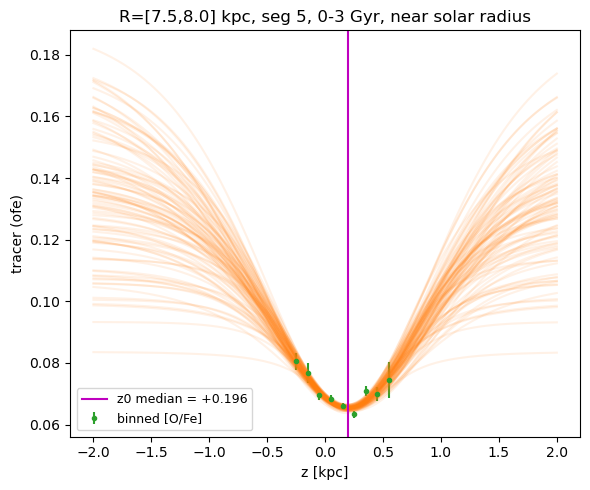

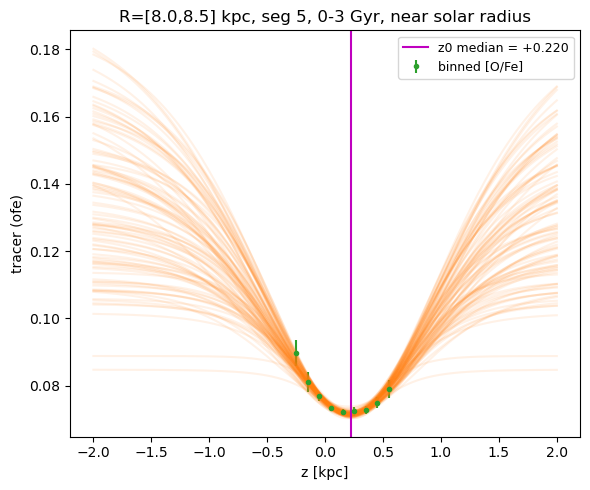

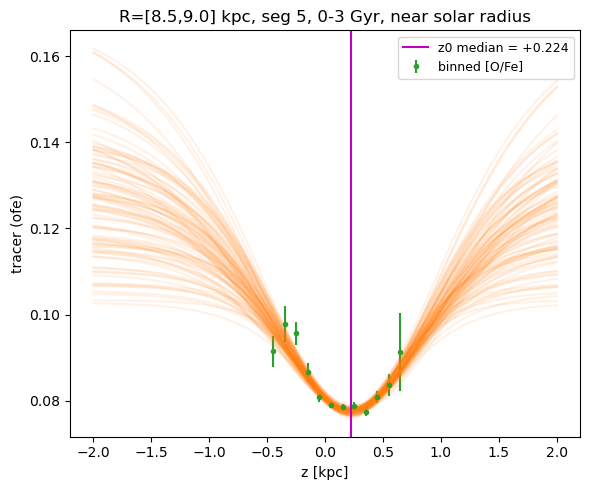

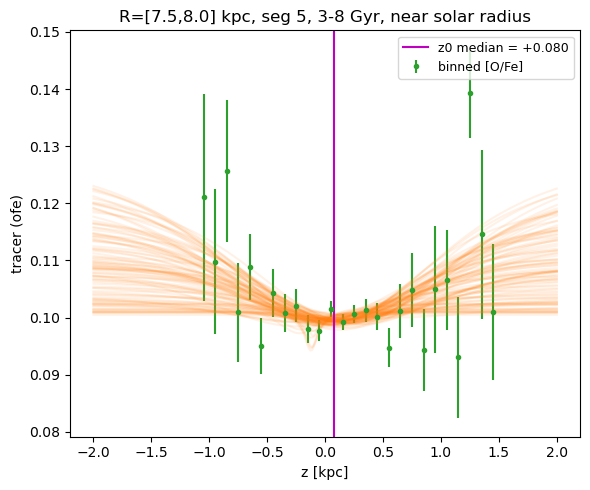

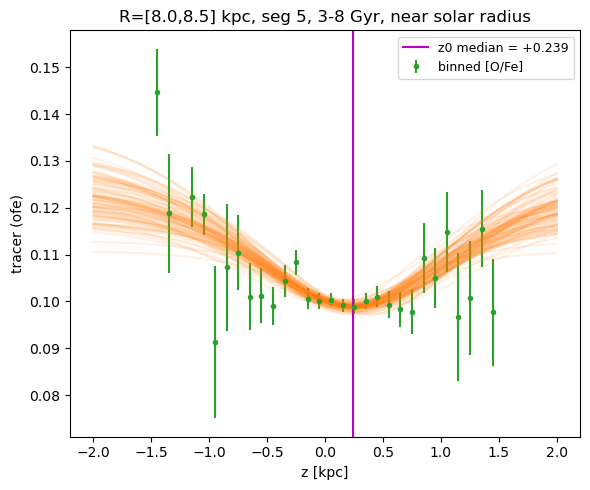

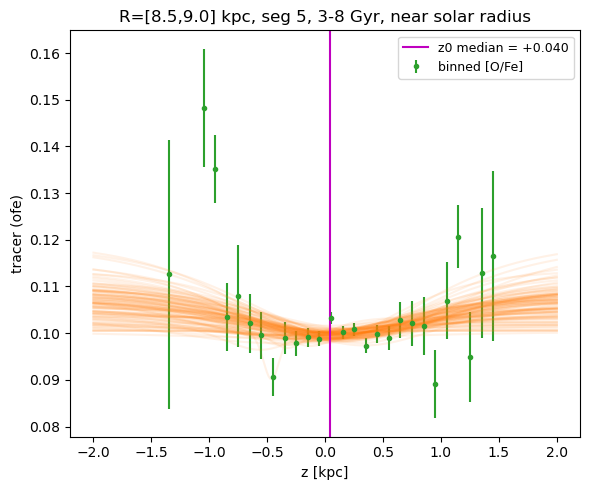

In [41]:
for age_label in ["0-3", "3-8"]:
    d = prepared_by_age[age_label]
    theta_edges = np.unwrap(np.array(d["crowd_bounds"], float))
    for i in range(1, len(theta_edges)):
        while theta_edges[i] <= theta_edges[i - 1]:
            theta_edges[i] += 2 * np.pi

    j_seg_focus = None
    for idx, seg_id in enumerate(d["SEG_PLOT_heat"]):
        a, b = theta_edges[idx], theta_edges[idx + 1]
        if between_ccw(np.array([phi0]), a, b)[0]:
            j_seg_focus = idx
            break

    i_R_focus = np.searchsorted(R_edges, R_sun) - 1

    for i_R in range(max(i_R_focus - 1, 0), min(i_R_focus + 2, len(R_edges) - 1)):
        z0_grid = z0_summary_age[age_label]["z0_med"]
        z0_err_grid = z0_summary_age[age_label]["z0_std"]
        val = z0_grid[i_R, j_seg_focus] if j_seg_focus is not None else np.nan
        if np.isfinite(val):
            plot_cell_fit(per_cell_z0_age[age_label], i_R, j_seg_focus, R_edges,
                          title_extra=f", {age_label} Gyr, near solar radius")
        else:
            print(f"{age_label}: R=[{R_edges[i_R]:.1f},{R_edges[i_R+1]:.1f}] seg {j_seg_focus} has no valid fit")

In [28]:
per_R_flare_age = {}
flare_summary_age = {}

for age_label, d in prepared_by_age.items():
    in_wedge = np.zeros_like(d["R"], dtype=bool)
    for i in d["SEG_PLOT_heat"]:
        in_wedge |= d["segm"][i]

    R_w = d["R"][in_wedge]
    z_w = d["z"][in_wedge]
    tracer_w = d["tracer"][in_wedge]
    tracer_err_w = d["tracer_err"][in_wedge]

    per_R_flare_age[age_label] = mm.fit_flare_bin(
        R_w, z_w, tracer_w, tracer_err_w, R_centers,
        model_fn=mm.model_h_eff,
        R_width=1.0,
        label=f"merger_{age_label}_flare",
        results_path=f"sim_flare_fit_merger_{age_label}.pkl",
        minN_total=minN_seg_total,
        min_bin_count=min_bin_count,
        min_bins_for_fit=min_bins_for_fit,
        z_fit_min=z_fit_min, z_fit_max=z_fit_max,
    )

    h_eff_med_flare, h_eff_std_flare = mm.compute_h_eff_flare(per_R_flare_age[age_label])
    flare_summary_age[age_label] = dict(h_eff_med=h_eff_med_flare, h_eff_std=h_eff_std_flare)

[merger_0-3_flare] fitting radial bins:   0%|            | 0/30 [00:00<?, ?it/s]/Users/emmatasso/outerdisk/midplane_model.py:194: RuntimeWarning: invalid value encountered in divide
  mean_tracer = stat1.statistic / stat2.statistic
/Users/emmatasso/outerdisk/midplane_model.py:195: RuntimeWarning: divide by zero encountered in divide
  mean_tracer_err = np.sqrt(1 / stat2.statistic + intrinsic_scatter ** 2)
/Users/emmatasso/outerdisk/midplane_model.py:206: UserWarning: There are not enough devices to run parallel chains: expected 2 but got 1. Chains will be drawn sequentially. If you are running MCMC in CPU, consider using `numpyro.set_host_device_count(2)` at the beginning of your program. You can double-check how many devices are available in your system using `jax.local_device_count()`.
  sampler = infer.MCMC(


[merger_0-3_flare] R=[0.2,1.2]: skipping, only 5 good bins
[merger_0-3_flare] R=[0.8,1.8]: skipping, only 5 good bins
[merger_0-3_flare] R=[1.2,2.2]: skipping, only 7 good bins


[merger_0-3_flare] fitting radial bins:  13%|▌   | 4/30 [00:05<00:38,  1.46s/it]

[merger_0-3_flare] R=[1.8,2.8]: fit ok, n_stars=799


[merger_0-3_flare] fitting radial bins:  17%|▋   | 5/30 [00:11<01:03,  2.54s/it]

...

[merger_8+_flare] fitting radial bins:  97%|███▊| 29/30 [05:06<00:06,  6.81s/it]

[merger_8+_flare] R=[14.2,15.2]: fit ok, n_stars=95103


[merger_8+_flare] fitting radial bins: 100%|████| 30/30 [05:12<00:00, 10.41s/it]


[merger_8+_flare] R=[14.8,15.8]: fit ok, n_stars=82772
[merger_8+_flare] fits complete: 30/30
[merger_8+_flare] saved to sim_flare_fit_merger_8+.pkl


computing flare h_eff: 100%|████████████████████| 30/30 [03:57<00:00,  7.92s/it]


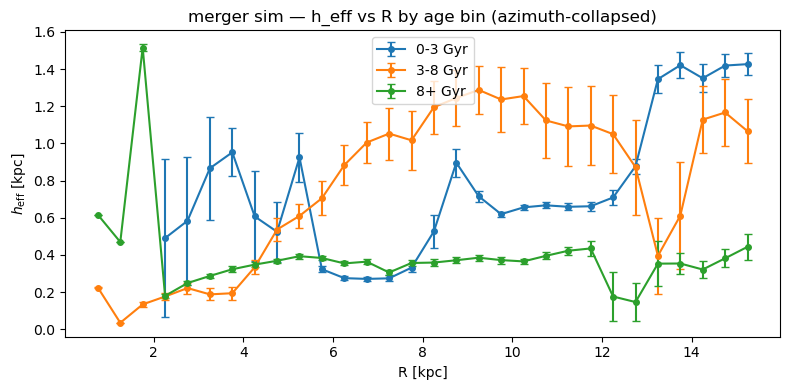

In [29]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 4))
age_colors = {"0-3": "C0", "3-8": "C1", "8+": "C2"}

for age_label in AGE_BINS:
    ax.errorbar(
        R_centers, flare_summary_age[age_label]["h_eff_med"], yerr=flare_summary_age[age_label]["h_eff_std"],
        fmt="o-", ms=4, capsize=3, color=age_colors[age_label], label=f"{age_label} Gyr",
    )

ax.set_xlabel("R [kpc]")
ax.set_ylabel(r"$h_\mathrm{eff}$ [kpc]")
ax.legend()
ax.set_title("merger sim — h_eff vs R by age bin (azimuth-collapsed)")
plt.tight_layout()
plt.show()

In [44]:
for age_label in ["0-3", "3-8", "8+"]:
    summary = flare_summary_age[age_label]
    per_R = per_R_flare_age[age_label]

    print(f"\n=== {age_label} Gyr: flare bins, ranked by relative error (std/med) ===")
    rows = []
    for i_R, cell in per_R.items():
        med = summary["h_eff_med"][i_R]
        std = summary["h_eff_std"][i_R]
        if not np.isfinite(med) or med == 0:
            continue
        rel_err = std / abs(med)
        rows.append((rel_err, i_R, med, std, cell.get("n_stars", np.nan), cell["Rlo"], cell["Rhi"]))

    rows.sort(key=lambda x: -x[0])
    for rel_err, i_R, med, std, n_stars, Rlo, Rhi in rows[:8]:
        print(f"  R=[{Rlo:.1f},{Rhi:.1f}]: h_eff={med:.3f}±{std:.3f} (rel err {rel_err:.2f}), n_stars={n_stars}")


=== 0-3 Gyr: flare bins, ranked by relative error (std/med) ===
  R=[1.8,2.8]: h_eff=0.491±0.425 (rel err 0.87), n_stars=799
  R=[2.2,3.2]: h_eff=0.584±0.345 (rel err 0.59), n_stars=2365
  R=[3.8,4.8]: h_eff=0.607±0.242 (rel err 0.40), n_stars=9384
  R=[2.8,3.8]: h_eff=0.866±0.278 (rel err 0.32), n_stars=5510
  R=[4.2,5.2]: h_eff=0.525±0.162 (rel err 0.31), n_stars=11777
  R=[7.8,8.8]: h_eff=0.527±0.088 (rel err 0.17), n_stars=24006
  R=[4.8,5.8]: h_eff=0.925±0.132 (rel err 0.14), n_stars=16480
  R=[3.2,4.2]: h_eff=0.952±0.128 (rel err 0.13), n_stars=8060

=== 3-8 Gyr: flare bins, ranked by relative error (std/med) ===
  R=[12.8,13.8]: h_eff=0.395±0.204 (rel err 0.51), n_stars=125348
  R=[13.2,14.2]: h_eff=0.612±0.289 (rel err 0.47), n_stars=109540
  R=[12.2,13.2]: h_eff=0.873±0.256 (rel err 0.29), n_stars=140728
  R=[11.8,12.8]: h_eff=1.050±0.208 (rel err 0.20), n_stars=155392
  R=[10.8,11.8]: h_eff=1.092±0.212 (rel err 0.19), n_stars=177790
  R=[11.2,12.2]: h_eff=1.096±0.213 (rel er

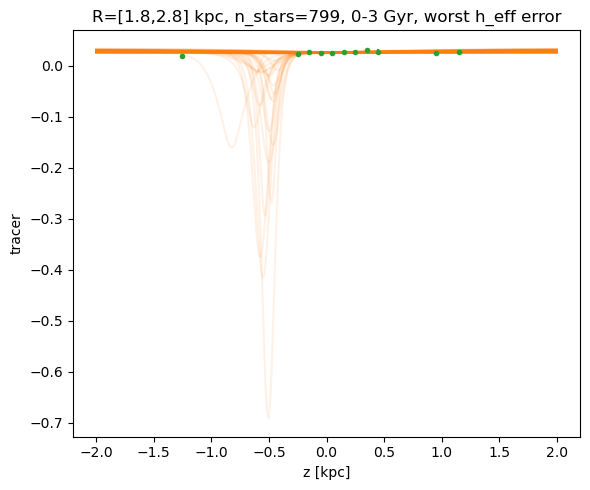

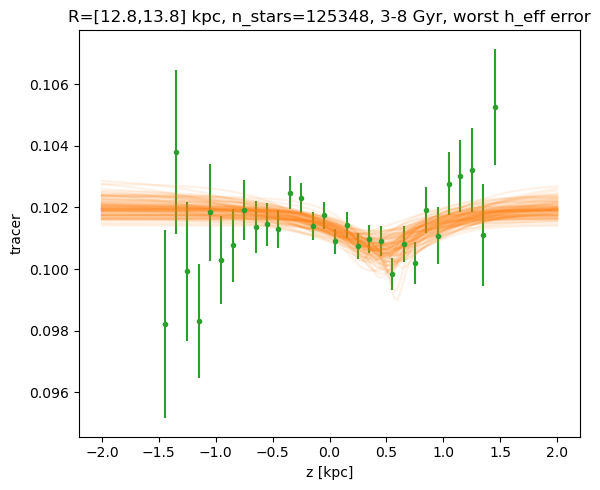

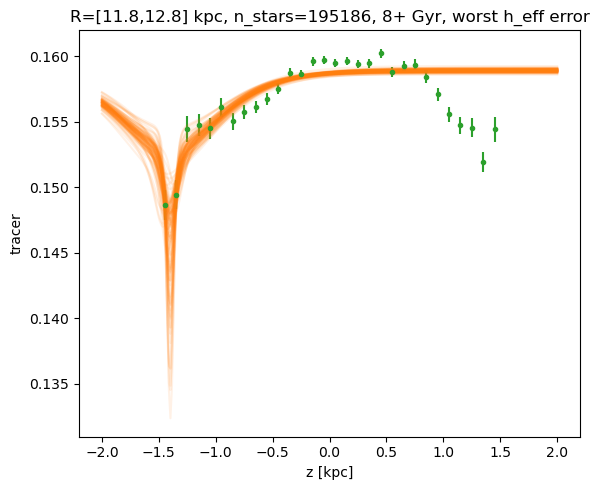

In [45]:
def plot_flare_cell_fit(per_R, i_R, title_extra=""):
    cell = per_R.get(i_R)
    if cell is None:
        print(f"no flare cell data for i_R={i_R}")
        return

    s = cell["samples"]
    z_grid = np.linspace(-2, 2, 300)

    fig, ax = plt.subplots(figsize=(6, 5))
    ax.errorbar(cell["z_binc"], cell["mean"], yerr=cell["err"],
                color="C2", linestyle="", marker=".", label="binned tracer")

    for i in range(min(100, len(s["A1"]))):
        cs = {k: v[i] for k, v in s.items()}
        cs["h2"] = cs["h1"] + cs["d_h2"]
        y_pred = mm.mixture_of_sech2(z_grid, cs["A1"], cs["A2"], cs["h1"], cs["h2"], cs["z0"]) + cs["offset"]
        ax.plot(z_grid, y_pred, color="C1", alpha=0.1)

    ax.set_xlabel("z [kpc]")
    ax.set_ylabel("tracer")
    ax.set_title(f"R=[{cell['Rlo']:.1f},{cell['Rhi']:.1f}] kpc, n_stars={cell.get('n_stars','?')}{title_extra}")
    plt.tight_layout()
    plt.show()


for age_label in ["0-3", "3-8", "8+"]:
    per_R = per_R_flare_age[age_label]
    summary = flare_summary_age[age_label]
    rel_errs = []
    for i_R, cell in per_R.items():
        med, std = summary["h_eff_med"][i_R], summary["h_eff_std"][i_R]
        if np.isfinite(med) and med != 0:
            rel_errs.append((std/abs(med), i_R))
    rel_errs.sort(key=lambda x: -x[0])
    if rel_errs:
        worst_i_R = rel_errs[0][1]
        plot_flare_cell_fit(per_R, worst_i_R, title_extra=f", {age_label} Gyr, worst h_eff error")

## density method

In [19]:
import numpy as np
from scipy.optimize import curve_fit
from itertools import product

def sech2_density_np(z, A1, A2, h1, h2, z0):
    dz = z - z0
    return A1 / np.cosh(dz / h1)**2 + A2 / np.cosh(dz / h2)**2

def fit_sech2_density_curvefit(z_binc, count, count_err):
    A_guess = max(count.max(), 1.0)
    p0 = [A_guess * 0.7, A_guess * 0.3, 0.3, 0.6, 0.0]
    bounds = (
        [0, 0, 0.04, 0.08, -0.5],
        [A_guess * 5, A_guess * 5, 1.0, 1.75, 0.5],
    )
    try:
        popt, pcov = curve_fit(
            sech2_density_np, z_binc, count, p0=p0, sigma=count_err,
            absolute_sigma=True, bounds=bounds, maxfev=5000,
        )
        z0_val = popt[4]
        z0_err = np.sqrt(pcov[4, 4]) if np.isfinite(pcov[4, 4]) else np.nan
        return z0_val, z0_err, True
    except Exception:
        return np.nan, np.nan, False

In [12]:
Z_BINS_FIT = np.arange(-5, 5 + 1e-3, 0.1)

def bin_one_density(z, z_bins=Z_BINS_FIT):
    count, edges = np.histogram(z, bins=z_bins)
    z_binc = 0.5 * (edges[1:] + edges[:-1])
    count_err = np.sqrt(np.maximum(count, 1))
    return z_binc, count.astype(float), count_err

def select_annulus_segment_density(R_use, Z_use, seg_mask, Rmin, Rmax,
                                    min_bin_count=5, min_bins_for_fit=8,
                                    z_fit_min=-1.5, z_fit_max=1.5, minN_total=15):
    m = seg_mask & (R_use >= Rmin) & (R_use < Rmax) & np.isfinite(Z_use)
    n_stars = int(m.sum())
    if n_stars < minN_total:
        return None, None, None, n_stars, False

    z_binc, count, count_err = bin_one_density(Z_use[m])
    good = (count >= min_bin_count) & (z_binc >= z_fit_min) & (z_binc <= z_fit_max)
    if good.sum() < min_bins_for_fit:
        return None, None, None, n_stars, False

    return z_binc[good], count[good], count_err[good], n_stars, True

In [21]:
per_cell_z0_density = {}
z0_density_summary = {}

for name, d in prepared.items():
    n_R, n_seg = len(R_edges) - 1, len(d["SEG_PLOT_heat"])
    z0_med  = np.full((n_R, n_seg), np.nan)
    z0_std  = np.full((n_R, n_seg), np.nan)
    ok_grid = np.zeros((n_R, n_seg), dtype=bool)

    pairs = list(product(range(n_R), range(n_seg)))
    for k, (i_R, j_seg) in enumerate(pairs, 1):
        Rmin, Rmax = float(R_edges[i_R]), float(R_edges[i_R + 1])
        seg_id = d["SEG_PLOT_heat"][j_seg]
        z_binc_k, count_k, err_k, ns_k, ok_k = select_annulus_segment_density(
            d["R"], d["z"], d["segm"][seg_id], Rmin, Rmax)
        if not ok_k:
            continue

        z0_val, z0_err, fit_ok = fit_sech2_density_curvefit(z_binc_k, count_k, err_k)
        if fit_ok:
            z0_med[i_R, j_seg] = z0_val
            z0_std[i_R, j_seg] = z0_err
            ok_grid[i_R, j_seg] = True

    print(f"{name} density fits complete:", int(ok_grid.sum()), "/", ok_grid.size)
    z0_density_summary[name] = dict(z0_med=z0_med, z0_std=z0_std, ok_grid=ok_grid)

merger density fits complete: 330 / 330
host density fits complete: 330 / 330


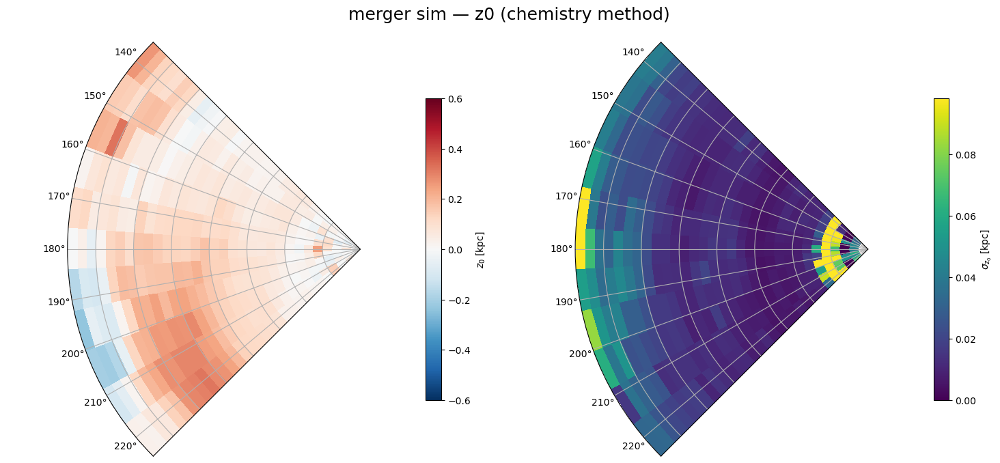

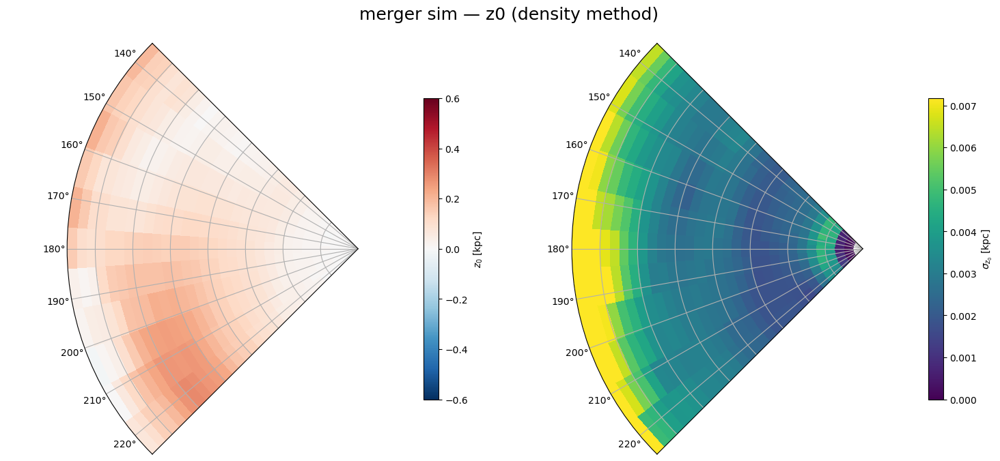

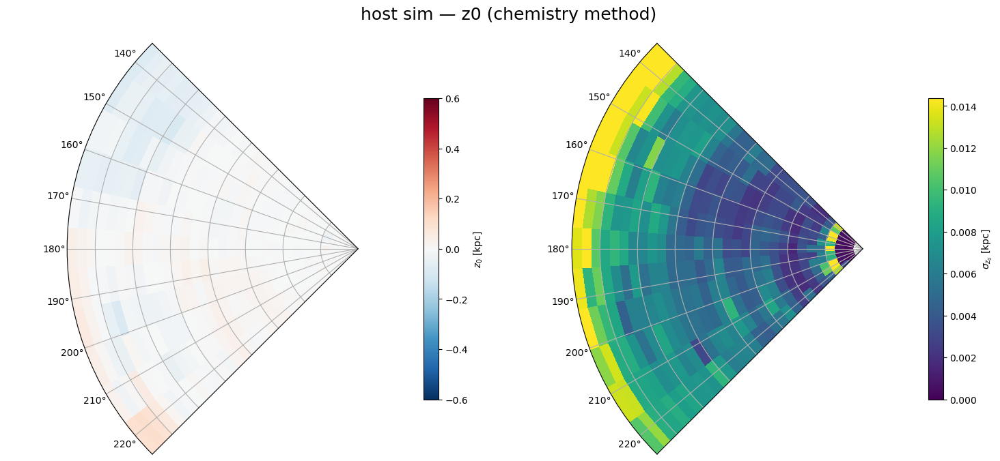

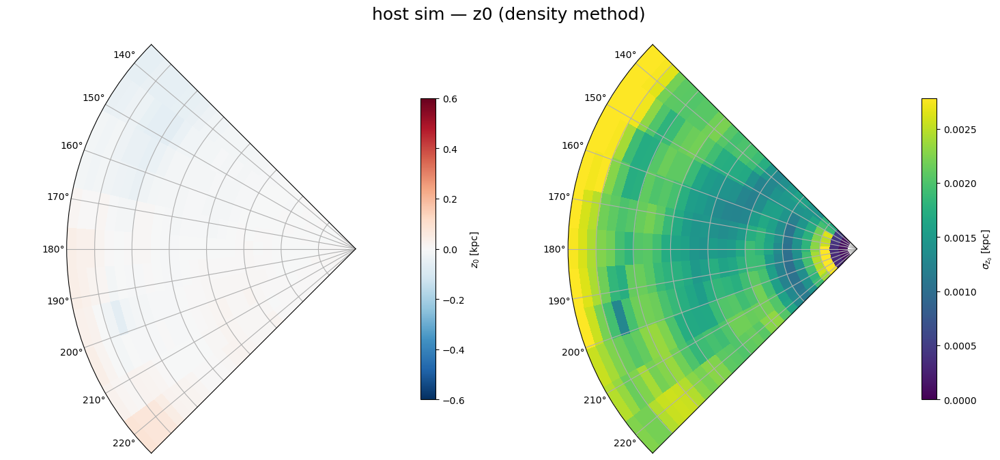

In [22]:
for name, d in prepared.items():
    plot_z0_heatmap_sim(
        z0_summary[name]["z0_med"], z0_summary[name]["z0_std"],
        f"{name} sim — z0 (chemistry method)", d["crowd_bounds"], len(d["SEG_PLOT_heat"])
    )
    plot_z0_heatmap_sim(
        z0_density_summary[name]["z0_med"], z0_density_summary[name]["z0_std"],
        f"{name} sim — z0 (density method)", d["crowd_bounds"], len(d["SEG_PLOT_heat"])
    )

## just thin disk

merger: 1259437 thin-disc stars after R<16 cut, 315390 in the fit wedge (vs 944047 outside it)
host: 921477 thin-disc stars after R<16 cut, 238296 in the fit wedge (vs 683181 outside it)


[merger_z0_thindisc] grid fit:   0%|                    | 0/330 [00:00<?, ?it/s]/Users/emmatasso/outerdisk/midplane_model.py:194: RuntimeWarning: invalid value encountered in divide
  mean_tracer = stat1.statistic / stat2.statistic
/Users/emmatasso/outerdisk/midplane_model.py:195: RuntimeWarning: divide by zero encountered in divide
  mean_tracer_err = np.sqrt(1 / stat2.statistic + intrinsic_scatter ** 2)
/Users/emmatasso/outerdisk/midplane_model.py:206: UserWarning: There are not enough devices to run parallel chains: expected 2 but got 1. Chains will be drawn sequentially. If you are running MCMC in CPU, consider using `numpyro.set_host_device_count(2)` at the beginning of your program. You can double-check how many devices are available in your system using `jax.local_device_count()`.
  sampler = infer.MCMC(
[merger_z0_thindisc] grid fit: 100%|██████████| 330/330 [43:01<00:00,  7.82s/it]


[merger_z0_thindisc] grid fits complete: 330/330
[merger_z0_thindisc] saved to sim_grid_fit_z0_merger_thindisc.pkl


[host_z0_thindisc] grid fit: 100%|████████████| 330/330 [16:51<00:00,  3.06s/it]


[host_z0_thindisc] grid fits complete: 330/330
[host_z0_thindisc] saved to sim_grid_fit_z0_host_thindisc.pkl


summarizing grid fit: 100%|███████████████████| 330/330 [03:59<00:00,  1.38it/s]


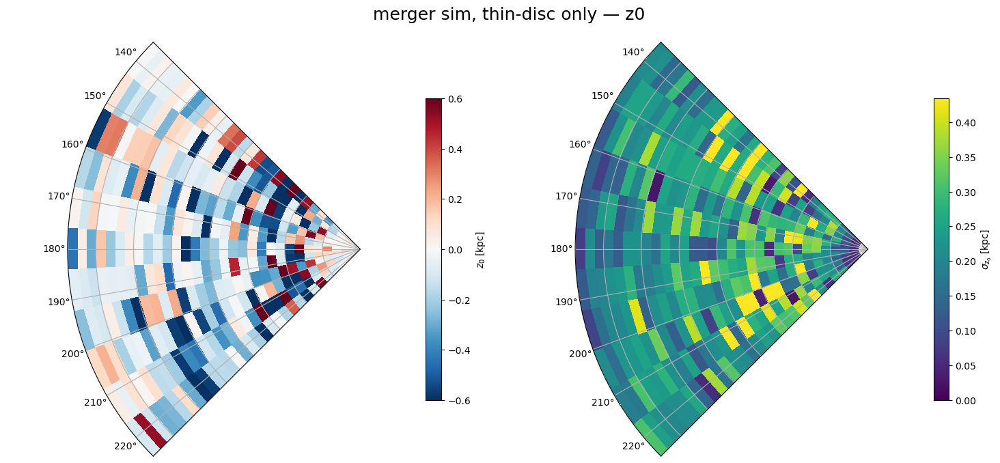

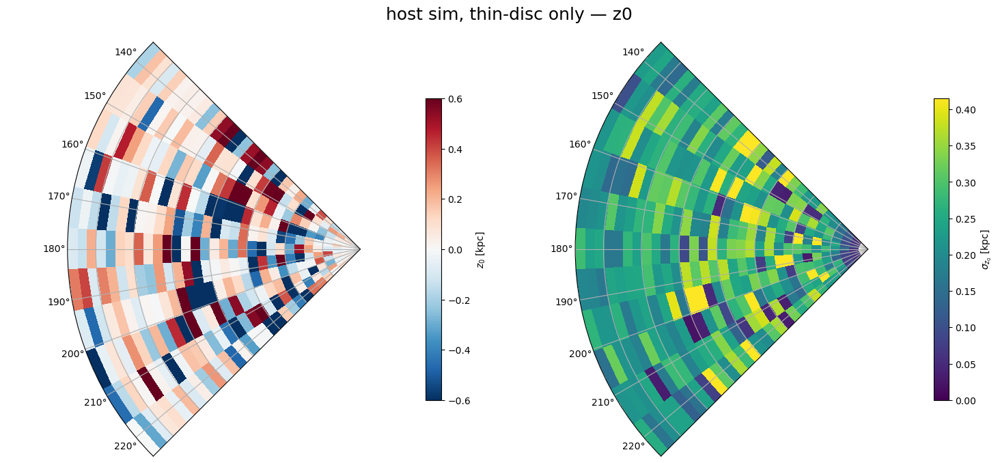

In [35]:
import numpy as np
import pandas as pd
import os
import pickle
from src.coords import build_segment_setup

# --- build a thin-disk-only version of `prepared`, using the tagged parquet files ---
sims_tagged = {
    "merger": pd.read_parquet("merger_sim_disc_all.parquet"),
    "host":   pd.read_parquet("host_sim_disc_all.parquet"),
}

prepared_thin = {}

for name, df in sims_tagged.items():
    R = df["R"].to_numpy()
    z = df["z"].to_numpy()
    phi = df["phi"].to_numpy()
    tracer = df["ofe"].to_numpy()
    is_thin_disc = df["is_thin_disc"].to_numpy()

    finite = np.isfinite(R) & np.isfinite(z) & np.isfinite(phi) & np.isfinite(tracer)
    keep = finite & is_thin_disc & (R < 16.0)

    R = R[keep]
    z = z[keep]
    phi = phi[keep]
    tracer = tracer[keep]
    tracer_err = np.full_like(tracer, OFE_ERR_PLACEHOLDER, dtype=float)

    segm, crowd_bounds, window_edges, seg_diag = build_segment_setup(
        phi, phi0=phi0, crowd_halfwidth_deg=45, n_crowd=11
    )
    SEG_PLOT_heat = list(range(1, seg_diag["n_crowd"] + 1))

    prepared_thin[name] = dict(
        R=R, z=z, phi=phi, tracer=tracer, tracer_err=tracer_err,
        segm=segm, crowd_bounds=crowd_bounds, window_edges=window_edges,
        SEG_PLOT_heat=SEG_PLOT_heat,
    )

    print(f"{name}: {len(R)} thin-disc stars after R<16 cut, "
          f"{sum(segm[i].sum() for i in SEG_PLOT_heat)} in the fit wedge "
          f"(vs {segm[seg_diag['seg_rest_id']].sum()} outside it)")

# --- run the sech2 z0 fit (same as cell 3, but on prepared_thin) ---
per_cell_z0_thin = {}
z0_summary_thin = {}

FORCE_RERUN = False   # set True to ignore any cached .pkl and refit everything

for name, d in prepared_thin.items():
    seg_masks_fit = {i: d["segm"][i] for i in d["SEG_PLOT_heat"]}
    results_path = f"sim_grid_fit_z0_{name}_thindisc.pkl"

    if os.path.exists(results_path) and not FORCE_RERUN:
        print(f"[{name}_z0_thindisc] loading cached fit from {results_path}")
        with open(results_path, "rb") as f:
            cached = pickle.load(f)
        per_cell_z0_thin[name] = cached["per_cell"]
    else:
        per_cell_z0_thin[name] = mm.run_grid_fit(
            d["R"], d["z"], d["tracer"], d["tracer_err"],
            seg_masks_fit, R_edges,
            model_fn=mm.model_z0,
            label=f"{name}_z0_thindisc",
            results_path=results_path,
            minN_total=minN_seg_total,
            min_bin_count=min_bin_count,
            min_bins_for_fit=min_bins_for_fit,
            z_fit_min=z_fit_min, z_fit_max=z_fit_max,
        )

    z0_med, z0_std, _, _ = mm.summarize_grid_fit(
        per_cell_z0_thin[name], n_R=len(R_edges) - 1, n_seg=len(seg_masks_fit)
    )
    z0_summary_thin[name] = dict(z0_med=z0_med, z0_std=z0_std)

# --- plot, reusing the plot_z0_heatmap_sim function already defined in cell 6 ---
for name, d in prepared_thin.items():
    zlim = 0.6
    plot_z0_heatmap_sim(
        z0_summary_thin[name]["z0_med"], z0_summary_thin[name]["z0_std"],
        f"{name} sim, thin-disc only — z0", d["crowd_bounds"], len(d["SEG_PLOT_heat"])
    )

merger: 1106135 new_mw stars after R<16 cut, 277276 in the fit wedge (vs 828859 outside it)


[merger_z0_newmw] grid fit:   0%|                       | 0/330 [00:00<?, ?it/s]/Users/emmatasso/outerdisk/midplane_model.py:194: RuntimeWarning: invalid value encountered in divide
  mean_tracer = stat1.statistic / stat2.statistic
/Users/emmatasso/outerdisk/midplane_model.py:195: RuntimeWarning: divide by zero encountered in divide
  mean_tracer_err = np.sqrt(1 / stat2.statistic + intrinsic_scatter ** 2)
/Users/emmatasso/outerdisk/midplane_model.py:206: UserWarning: There are not enough devices to run parallel chains: expected 2 but got 1. Chains will be drawn sequentially. If you are running MCMC in CPU, consider using `numpyro.set_host_device_count(2)` at the beginning of your program. You can double-check how many devices are available in your system using `jax.local_device_count()`.
  sampler = infer.MCMC(
[merger_z0_newmw] grid fit: 100%|█████████████| 330/330 [15:27<00:00,  2.81s/it]


[merger_z0_newmw] grid fits complete: 321/330
[merger_z0_newmw] saved to sim_grid_fit_z0_merger_newmw.pkl


summarizing grid fit: 100%|███████████████████| 321/321 [03:33<00:00,  1.51it/s]


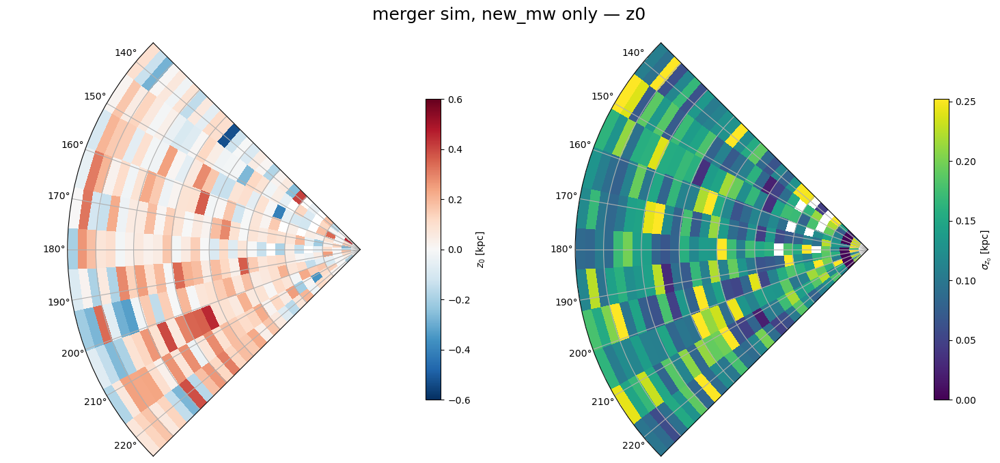

In [36]:
import numpy as np
import pandas as pd
import os
import pickle
from src.coords import build_segment_setup

# --- build a new_mw-only version of `prepared`, merger sim only ---
merger_all = pd.read_parquet("merger_sim_disc_all.parquet")

R = merger_all["R"].to_numpy()
z = merger_all["z"].to_numpy()
phi = merger_all["phi"].to_numpy()
tracer = merger_all["ofe"].to_numpy()
is_new_mw = merger_all["is_new_mw"].to_numpy()

finite = np.isfinite(R) & np.isfinite(z) & np.isfinite(phi) & np.isfinite(tracer)
keep = finite & is_new_mw & (R < 16.0)

R = R[keep]
z = z[keep]
phi = phi[keep]
tracer = tracer[keep]
tracer_err = np.full_like(tracer, OFE_ERR_PLACEHOLDER, dtype=float)

segm, crowd_bounds, window_edges, seg_diag = build_segment_setup(
    phi, phi0=phi0, crowd_halfwidth_deg=45, n_crowd=11
)
SEG_PLOT_heat = list(range(1, seg_diag["n_crowd"] + 1))

d_newmw = dict(
    R=R, z=z, phi=phi, tracer=tracer, tracer_err=tracer_err,
    segm=segm, crowd_bounds=crowd_bounds, window_edges=window_edges,
    SEG_PLOT_heat=SEG_PLOT_heat,
)

print(f"merger: {len(R)} new_mw stars after R<16 cut, "
      f"{sum(segm[i].sum() for i in SEG_PLOT_heat)} in the fit wedge "
      f"(vs {segm[seg_diag['seg_rest_id']].sum()} outside it)")

# --- run the sech2 z0 fit (same as cell 3, but on this new_mw-only merger sample) ---
seg_masks_fit = {i: d_newmw["segm"][i] for i in d_newmw["SEG_PLOT_heat"]}
results_path = "sim_grid_fit_z0_merger_newmw.pkl"

FORCE_RERUN = False

if os.path.exists(results_path) and not FORCE_RERUN:
    print(f"loading cached fit from {results_path}")
    with open(results_path, "rb") as f:
        cached = pickle.load(f)
    per_cell_z0_newmw = cached["per_cell"]
else:
    per_cell_z0_newmw = mm.run_grid_fit(
        d_newmw["R"], d_newmw["z"], d_newmw["tracer"], d_newmw["tracer_err"],
        seg_masks_fit, R_edges,
        model_fn=mm.model_z0,
        label="merger_z0_newmw",
        results_path=results_path,
        minN_total=minN_seg_total,
        min_bin_count=min_bin_count,
        min_bins_for_fit=min_bins_for_fit,
        z_fit_min=z_fit_min, z_fit_max=z_fit_max,
    )

z0_med_newmw, z0_std_newmw, _, _ = mm.summarize_grid_fit(
    per_cell_z0_newmw, n_R=len(R_edges) - 1, n_seg=len(seg_masks_fit)
)

# --- plot, reusing plot_z0_heatmap_sim already defined in this notebook ---
zlim = 0.6
plot_z0_heatmap_sim(
    z0_med_newmw, z0_std_newmw,
    "merger sim, new_mw only — z0", d_newmw["crowd_bounds"], len(d_newmw["SEG_PLOT_heat"])
)

merger, thin_disc only (median-z method): 330/330 cells with >= 30 stars


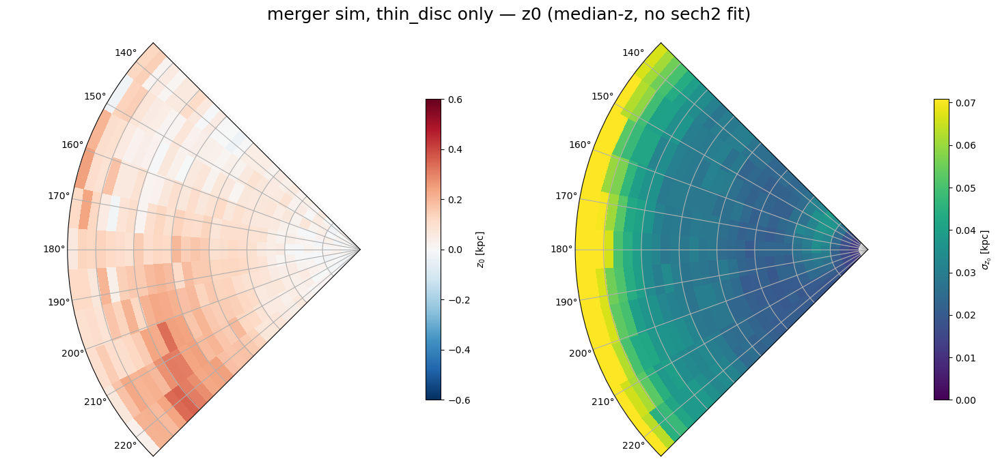

merger, new_mw only (median-z method): 330/330 cells with >= 30 stars


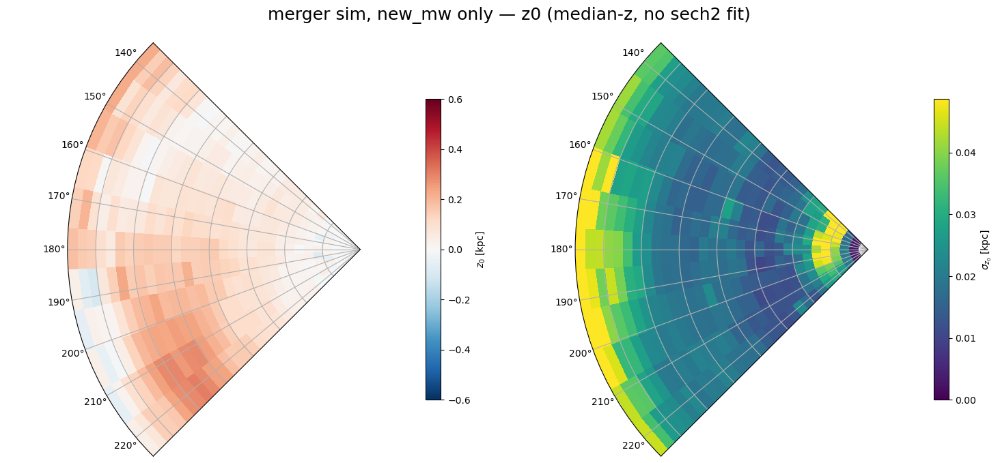

In [37]:
import numpy as np
import pandas as pd
from src.coords import build_segment_setup

MIN_N = 30   # minimum stars per (R, phi) cell to trust the median

def compute_z0_grid_median(R, z, phi, segm, seg_ids, R_edges, min_n=MIN_N):
    n_R = len(R_edges) - 1
    n_seg = len(seg_ids)
    z0_med = np.full((n_R, n_seg), np.nan)
    z0_std = np.full((n_R, n_seg), np.nan)

    for i_R in range(n_R):
        Rmin, Rmax = R_edges[i_R], R_edges[i_R + 1]
        R_mask = (R >= Rmin) & (R < Rmax)
        for j, seg_id in enumerate(seg_ids):
            m = R_mask & segm[seg_id]
            n = int(m.sum())
            if n >= min_n:
                zvals = z[m]
                med = np.median(zvals)
                se = 1.2533 * np.std(zvals, ddof=1) / np.sqrt(n)  # standard error of the median
                z0_med[i_R, j] = med
                z0_std[i_R, j] = se

    return z0_med, z0_std

merger_all = pd.read_parquet("merger_sim_disc_all.parquet")

R_full = merger_all["R"].to_numpy()
z_full = merger_all["z"].to_numpy()
phi_full = merger_all["phi"].to_numpy()
is_thin_disc = merger_all["is_thin_disc"].to_numpy()
is_new_mw = merger_all["is_new_mw"].to_numpy()

finite = np.isfinite(R_full) & np.isfinite(z_full) & np.isfinite(phi_full)

for tag_name, tag_mask in [("thin_disc", is_thin_disc), ("new_mw", is_new_mw)]:
    keep = finite & tag_mask & (R_full < 16.0)

    R = R_full[keep]
    z = z_full[keep]
    phi = phi_full[keep]

    segm, crowd_bounds, window_edges, seg_diag = build_segment_setup(
        phi, phi0=phi0, crowd_halfwidth_deg=45, n_crowd=11
    )
    seg_ids = list(range(1, seg_diag["n_crowd"] + 1))

    z0_med, z0_std = compute_z0_grid_median(R, z, phi, segm, seg_ids, R_edges, min_n=MIN_N)

    print(f"merger, {tag_name} only (median-z method): "
          f"{np.isfinite(z0_med).sum()}/{z0_med.size} cells with >= {MIN_N} stars")

    zlim = 0.6
    plot_z0_heatmap_sim(
        z0_med, z0_std,
        f"merger sim, {tag_name} only — z0 (median-z, no sech2 fit)",
        crowd_bounds, len(seg_ids)
    )

In [38]:
import numpy as np
import pandas as pd
from src.coords import build_segment_setup

def count_stars_per_cell(R, phi, segm, seg_ids, R_edges):
    n_R = len(R_edges) - 1
    n_seg = len(seg_ids)
    counts = np.zeros((n_R, n_seg), dtype=int)
    for i_R in range(n_R):
        Rmin, Rmax = R_edges[i_R], R_edges[i_R + 1]
        R_mask = (R >= Rmin) & (R < Rmax)
        for j, seg_id in enumerate(seg_ids):
            counts[i_R, j] = int((R_mask & segm[seg_id]).sum())
    return counts

merger_all = pd.read_parquet("merger_sim_disc_all.parquet")
merger_full_csv = pd.read_csv("sim_disc_merger.csv")   # the "prepared"/full sample used in cells 0-7

R_tagged = merger_all["R"].to_numpy()
phi_tagged = merger_all["phi"].to_numpy()
z_tagged = merger_all["z"].to_numpy()
ofe_tagged = merger_all["ofe"].to_numpy()
is_thin_disc = merger_all["is_thin_disc"].to_numpy()
is_new_mw = merger_all["is_new_mw"].to_numpy()

finite_tagged = (np.isfinite(R_tagged) & np.isfinite(phi_tagged)
                  & np.isfinite(z_tagged) & np.isfinite(ofe_tagged))

R_full = merger_full_csv["R"].to_numpy()
phi_full = merger_full_csv["phi"].to_numpy()
z_full = merger_full_csv["z"].to_numpy()
ofe_full = merger_full_csv["ofe"].to_numpy()
finite_full = (np.isfinite(R_full) & np.isfinite(phi_full)
                & np.isfinite(z_full) & np.isfinite(ofe_full))

samples = {
    "new_mw only": (R_tagged[finite_tagged & is_new_mw & (R_tagged < 16.0)],
                     phi_tagged[finite_tagged & is_new_mw & (R_tagged < 16.0)]),
    "thin_disc only": (R_tagged[finite_tagged & is_thin_disc & (R_tagged < 16.0)],
                        phi_tagged[finite_tagged & is_thin_disc & (R_tagged < 16.0)]),
    "full/combined (prepared)": (R_full[finite_full & (R_full < 16.0)],
                                   phi_full[finite_full & (R_full < 16.0)]),
}

for label, (R, phi) in samples.items():
    segm, crowd_bounds, window_edges, seg_diag = build_segment_setup(
        phi, phi0=phi0, crowd_halfwidth_deg=45, n_crowd=11
    )
    seg_ids = list(range(1, seg_diag["n_crowd"] + 1))
    counts = count_stars_per_cell(R, phi, segm, seg_ids, R_edges)

    nonzero = counts[counts > 0]
    print(f"{label}: total={len(R):,} stars")
    print(f"  per-cell counts -> median={np.median(counts):.0f}, "
          f"25th pct={np.percentile(counts, 25):.0f}, "
          f"min={counts.min()}, max={counts.max()}")
    print(f"  cells below minN_seg_total ({minN_seg_total}): "
          f"{(counts < minN_seg_total).sum()}/{counts.size}")
    print(f"  cells below 100 stars: {(counts < 100).sum()}/{counts.size}")
    print(f"  cells below 500 stars: {(counts < 500).sum()}/{counts.size}")
    print()

new_mw only: total=1,106,135 stars
  per-cell counts -> median=432, 25th pct=331, min=132, max=6227
  cells below minN_seg_total (15): 0/330
  cells below 100 stars: 0/330
  cells below 500 stars: 219/330

thin_disc only: total=1,259,437 stars
  per-cell counts -> median=736, 25th pct=610, min=198, max=3524
  cells below minN_seg_total (15): 0/330
  cells below 100 stars: 0/330
  cells below 500 stars: 55/330

full/combined (prepared): total=39,919,183 stars
  per-cell counts -> median=20364, 25th pct=17122, min=6989, max=157154
  cells below minN_seg_total (15): 0/330
  cells below 100 stars: 0/330
  cells below 500 stars: 0/330



merger 42137146 stars
host 52647375 stars
merger: 39919183 stars after R<16 cut, 10011350 in the fit wedge (vs 29907833 outside it)
host: 49289381 stars after R<16 cut, 12666588 in the fit wedge (vs 36622793 outside it)
[merger_z0] loading cached fit from sim_grid_fit_z0_merger.pkl


summarizing grid fit: 100%|███████████████████| 330/330 [03:37<00:00,  1.51it/s]


[host_z0] loading cached fit from sim_grid_fit_z0_host.pkl


summarizing grid fit: 100%|███████████████████| 330/330 [03:38<00:00,  1.51it/s]


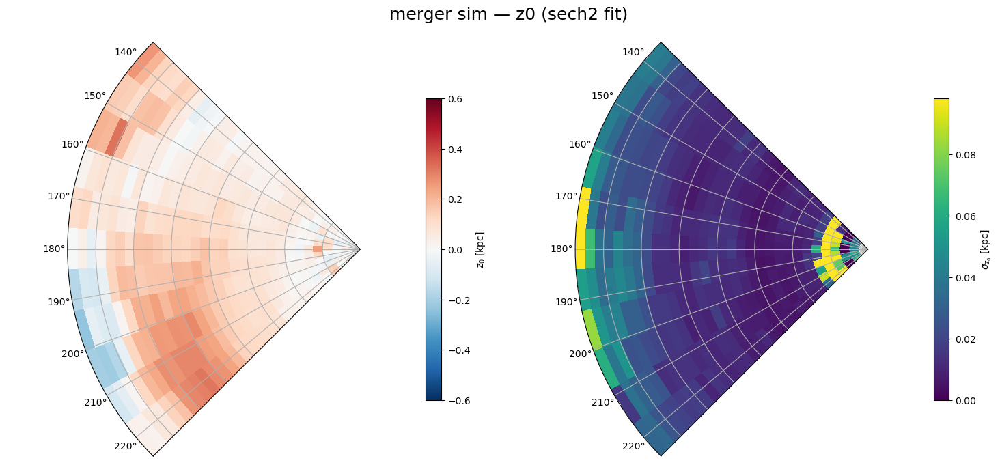

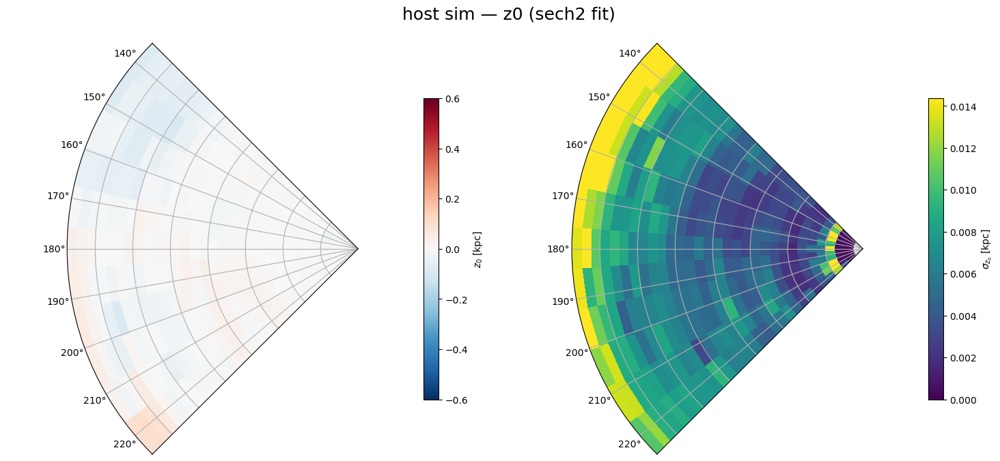

In [41]:
import numpy as np
import pandas as pd
import pickle
import os
import jax.numpy as jnp
import jax.random as jr
from itertools import product
import matplotlib.pyplot as plt

import midplane_model as mm
from src.coords import build_segment_setup, between_ccw

# --- Load the two sim extracts ---
sims = {
    "merger": pd.read_csv("sim_disc_merger.csv"),
    "host":   pd.read_csv("sim_disc_host.csv"),
}
for name, df in sims.items():
    print(name, len(df), "stars")

# --- Shared binning + fitting settings (matched to your real APOGEE pipeline) ---
z_edges          = np.linspace(-3.0, 3.0, 181)
R_edges          = np.arange(0.5, 15.5 + 0.5, 0.5)
minN_seg_total   = 15
min_bin_count    = 5
min_bins_for_fit = 8
z_fit_min, z_fit_max = -1.5, 1.5
zlim             = 0.6
R_centers        = 0.5 * (R_edges[:-1] + R_edges[1:])

mm.Z_BINS_FIT = z_edges

OFE_ERR_PLACEHOLDER = 1e-4
phi0 = np.pi

# --- prepare both sims (finite + R<16 cut, full population, no tag split) ---
prepared = {}

for name, df in sims.items():
    R = df["R"].to_numpy()
    z = df["z"].to_numpy()
    phi = df["phi"].to_numpy()
    tracer = df["ofe"].to_numpy()

    finite = np.isfinite(R) & np.isfinite(z) & np.isfinite(phi) & np.isfinite(tracer)
    keep = finite & (R < 16.0)

    R = R[keep]
    z = z[keep]
    phi = phi[keep]
    tracer = tracer[keep]
    tracer_err = np.full_like(tracer, OFE_ERR_PLACEHOLDER, dtype=float)

    segm, crowd_bounds, window_edges, seg_diag = build_segment_setup(
        phi, phi0=phi0, crowd_halfwidth_deg=45, n_crowd=11
    )
    SEG_PLOT_heat = list(range(1, seg_diag["n_crowd"] + 1))

    prepared[name] = dict(
        R=R, z=z, phi=phi, tracer=tracer, tracer_err=tracer_err,
        segm=segm, crowd_bounds=crowd_bounds, window_edges=window_edges,
        SEG_PLOT_heat=SEG_PLOT_heat,
    )

    print(f"{name}: {len(R)} stars after R<16 cut, "
          f"{sum(segm[i].sum() for i in SEG_PLOT_heat)} in the fit wedge "
          f"(vs {segm[seg_diag['seg_rest_id']].sum()} outside it)")

# --- run the sech2 z0 fit ---
per_cell_z0 = {}
z0_summary = {}

FORCE_RERUN = False   # set True to ignore any cached .pkl and refit everything

for name, d in prepared.items():
    seg_masks_fit = {i: d["segm"][i] for i in d["SEG_PLOT_heat"]}
    results_path = f"sim_grid_fit_z0_{name}.pkl"

    if os.path.exists(results_path) and not FORCE_RERUN:
        print(f"[{name}_z0] loading cached fit from {results_path}")
        with open(results_path, "rb") as f:
            cached = pickle.load(f)
        per_cell_z0[name] = cached["per_cell"]
    else:
        per_cell_z0[name] = mm.run_grid_fit(
            d["R"], d["z"], d["tracer"], d["tracer_err"],
            seg_masks_fit, R_edges,
            model_fn=mm.model_z0,
            label=f"{name}_z0",
            results_path=results_path,
            minN_total=minN_seg_total,
            min_bin_count=min_bin_count,
            min_bins_for_fit=min_bins_for_fit,
            z_fit_min=z_fit_min, z_fit_max=z_fit_max,
        )

    z0_med, z0_std, _, _ = mm.summarize_grid_fit(
        per_cell_z0[name], n_R=len(R_edges) - 1, n_seg=len(seg_masks_fit)
    )
    z0_summary[name] = dict(z0_med=z0_med, z0_std=z0_std)

# --- plot ---
def plot_z0_heatmap_sim(z0_med_bin, z0_std_bin, label, crowd_bounds, n_seg):
    theta_edges = np.unwrap(np.array(crowd_bounds, float))
    for i in range(1, len(theta_edges)):
        while theta_edges[i] <= theta_edges[i - 1]:
            theta_edges[i] += 2 * np.pi
    assert len(theta_edges) - 1 == n_seg

    T_mesh, R_mesh = np.meshgrid(theta_edges, R_edges)
    Zmap_med = np.ma.masked_invalid(z0_med_bin)
    Zmap_std = np.ma.masked_invalid(z0_std_bin)
    std_max = (float(np.nanpercentile(z0_std_bin[np.isfinite(z0_std_bin)], 95))
               if np.isfinite(z0_std_bin).any() else 1.0)
    theta_min, theta_max = theta_edges[0], theta_edges[-1]

    fig = plt.figure(figsize=(15, 7))
    fig.suptitle(label, fontsize=18)

    ax1 = plt.subplot(1, 2, 1, projection="polar")
    pcm1 = ax1.pcolormesh(T_mesh, R_mesh, Zmap_med, cmap="RdBu_r", vmin=-zlim, vmax=zlim, shading="flat")
    fig.colorbar(pcm1, ax=ax1, pad=0.01, shrink=0.7, label=r"$z_0$ [kpc]")
    ax1.set_theta_zero_location("E"); ax1.set_theta_direction(1)
    ax1.set_rmax(R_edges[-1])
    ax1.set_thetamin(np.degrees(theta_min)); ax1.set_thetamax(np.degrees(theta_max))
    ax1.set_yticklabels([])

    ax2 = plt.subplot(1, 2, 2, projection="polar")
    pcm2 = ax2.pcolormesh(T_mesh, R_mesh, Zmap_std, cmap="viridis", vmin=0.0, vmax=std_max, shading="flat")
    fig.colorbar(pcm2, ax=ax2, pad=0.01, shrink=0.7, label=r"$\sigma_{z_0}$ [kpc]")
    ax2.set_theta_zero_location("E"); ax2.set_theta_direction(1)
    ax2.set_rmax(R_edges[-1])
    ax2.set_thetamin(np.degrees(theta_min)); ax2.set_thetamax(np.degrees(theta_max))
    ax2.set_yticklabels([])

    plt.tight_layout()
    plt.show()

for name, d in prepared.items():
    plot_z0_heatmap_sim(
        z0_summary[name]["z0_med"], z0_summary[name]["z0_std"],
        f"{name} sim — z0 (sech2 fit)", d["crowd_bounds"], len(d["SEG_PLOT_heat"])
    )

In [49]:
for name, d in sims.items():
    print(f"=== {name} ===")
    print("columns:", list(d.columns))
    print("total rows:", len(d))
    for col in ["R", "phi", "z", "age", "feh", "ofe"]:
        if col in d.columns:
            vals = d[col].to_numpy()
            finite = np.isfinite(vals)
            print(f"  {col}: min={np.nanmin(vals):.3f}, max={np.nanmax(vals):.3f}, "
                  f"mean={np.nanmean(vals):.3f}, finite={finite.sum()}/{len(vals)}")
    print()

=== merger ===
columns: ['R', 'phi', 'z', 'age', 'feh', 'ofe']
total rows: 42137146
  R: min=0.000, max=97.118, mean=5.947, finite=42137146/42137146
  phi: min=-3.142, max=3.142, mean=-0.035, finite=42137146/42137146
  z: min=-23.105, max=34.440, mean=0.040, finite=42137146/42137146
  age: min=12.691, max=23.529, mean=15.809, finite=42137146/42137146
  feh: min=-2.712, max=0.883, mean=-0.148, finite=42137146/42137146
  ofe: min=-0.452, max=0.557, mean=0.125, finite=42137146/42137146

=== host ===
columns: ['R', 'phi', 'z', 'age', 'feh', 'ofe']
total rows: 52647375
  R: min=0.000, max=2916.035, mean=5.503, finite=52647375/52647375
  phi: min=-3.142, max=3.142, mean=0.014, finite=52647375/52647375
  z: min=-2666.372, max=2660.122, mean=-0.000, finite=52647375/52647375
  age: min=2.881, max=7.442, mean=5.125, finite=52647375/52647375
  feh: min=-2.712, max=0.981, mean=-0.106, finite=52647375/52647375
  ofe: min=-0.683, max=1.368, mean=0.143, finite=52647375/52647375



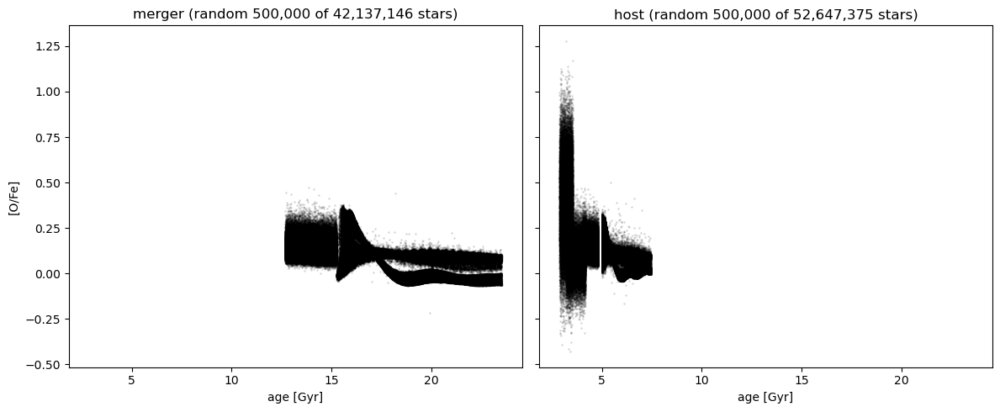

In [51]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(0)
N_PLOT = 500_000   # raise or lower as you like

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
for ax, name in zip(axes, ["merger", "host"]):
    df = sims[name]
    age = df["age"].to_numpy()
    ofe = df["ofe"].to_numpy()
    ok = np.isfinite(age) & np.isfinite(ofe)
    idx = rng.choice(np.where(ok)[0], size=min(N_PLOT, ok.sum()), replace=False)

    ax.scatter(age[idx], ofe[idx], s=1, alpha=0.1, color="k", rasterized=True)
    ax.set_title(f"{name} (random {len(idx):,} of {ok.sum():,} stars)")
    ax.set_xlabel("age [Gyr]")
axes[0].set_ylabel("[O/Fe]")
plt.tight_layout()
plt.show()

In [53]:
import numpy as np, pandas as pd

host = pd.read_csv("sim_disc_host.csv")
fix  = pd.read_csv("sim_disc_host_age_fix2.csv")

assert len(host) == len(fix), f"row mismatch: {len(host)} vs {len(fix)}"
assert np.allclose(host["feh"].to_numpy(), fix["feh"].to_numpy(), equal_nan=True), \
    "feh mismatch: row order does not line up, do not merge"

host["age"] = fix["age"].to_numpy()
host.to_csv("sim_disc_host(1).csv", index=False)   # leaves the original untouched
print("host age range:", host["age"].min(), "-", host["age"].max())   # expect about -0.5 to 13.9

FileNotFoundError: [Errno 2] No such file or directory: 'sim_disc_host_age_fix2.csv'